# Efficient Frontier & Downside Risk

**Research question — is the Sharpe-optimal portfolio also the least risky when markets fall?**

Mean-variance optimization picks the portfolio with the best return per unit of volatility: the *tangency portfolio*. But volatility treats gains and losses the same way, and it says nothing about how deep a portfolio falls on its worst days. This notebook builds the efficient frontier for a five-asset universe, then tests the tangency portfolio on two fronts: the **stability** of its weights and its **downside risk** compared with two simple alternatives.

| | |
|---|---|
| **Universe** | SPY (US equities), TLT (long-term US Treasuries), GLD (gold), VNQ (US REITs), BTC-USD (Bitcoin) |
| **Period** | January 2015 – December 2025, daily data |
| **Data** | Adjusted close prices from the Yahoo Finance API (`yfinance`), 3-month T-bill rate (DTB3) from the FRED API (`fredapi`) |
| **Portfolios compared** | Tangency (maximum Sharpe), minimum variance, equal weight (1/N), and the tangency portfolio diluted with T-bills to the minimum-variance volatility (equal-risk comparison) |
| **Risk measures** | Volatility, VaR and CVaR (historical, normal, Student t, Monte Carlo), stress tests, drawdowns, risk contributions |
| **Stack** | Python, pandas, NumPy, SciPy (SLSQP optimization, distributions), Matplotlib |

**Structure**
1. Data collection and quality control
2. Returns, correlations and portfolio variance
3. Efficient frontier (simulation and optimization)
4. Tangency portfolio and capital market line
5. Weight instability and out-of-sample test
6. Downside risk: VaR, CVaR, stress tests and risk contributions
7. Conclusion

> **Reproducibility.** The FRED API key is read from the `FRED_API_KEY` variable of a `.env` file (loaded with `python-dotenv`) and is never written in the notebook. Figures are saved in `assets/`.

In [1]:
# Setup — libraries and chart theme

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
import matplotlib.ticker as mtick
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.transforms import Bbox
from scipy import stats
from scipy.optimize import minimize
import yfinance as yf
from fredapi import Fred
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))        # loads FRED_API_KEY from the repository's .env file
os.makedirs("assets", exist_ok=True)

# Design tokens: one surface, three text levels, recessive grid
THEME = {
    "surface": "#fcfcfb", "card": "#ffffff", "ink": "#0b0b0b", "ink_2": "#52514e", "muted": "#898781",
    "grid": "#e6e5e0", "baseline": "#b9b8b3", "cloud": "#dddcd7", "band": "#f0efec",
}
# Colour follows the entity, never its rank (palette validated for colour-vision deficiency)
ASSET_COLORS = {"SPY": "#2a78d6", "TLT": "#1baf7a", "GLD": "#eda100", "VNQ": "#6250d6", "BTC-USD": "#e87ba4"}
PORTFOLIO_COLORS = {"Tangency": "#eb6834", "Diluted tangency": "#f4a27c",
                    "Minimum variance": "#2a78d6", "Equal weight": "#1baf7a"}
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a8282a"])
SOURCE_NOTE = "Sources: Yahoo Finance (adjusted prices), FRED (3-month T-bill, DTB3)  ·  Analysis: Didier Matton"
# Inter has a semibold weight; Arial and Helvetica only have bold (avoids font warnings in the outputs)
HAS_INTER = any(f.name == "Inter" for f in font_manager.fontManager.ttflist)
SEMIBOLD = "semibold" if HAS_INTER else "bold"


def apply_theme() -> None:
    """Global Matplotlib settings: typography, surface, recessive axes and grid."""
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Inter", "Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 10,
        "figure.facecolor": THEME["surface"], "axes.facecolor": THEME["surface"],
        "savefig.facecolor": THEME["surface"], "figure.dpi": 110,
        "axes.edgecolor": THEME["baseline"], "axes.linewidth": 0.8,
        "axes.labelcolor": THEME["ink_2"], "axes.labelsize": 10, "axes.labelpad": 8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
        "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
        "grid.color": THEME["grid"], "grid.linewidth": 0.8,
        "xtick.color": THEME["ink_2"], "ytick.color": THEME["ink_2"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "xtick.major.size": 0, "ytick.major.size": 0, "xtick.major.pad": 7, "ytick.major.pad": 7,
        "legend.frameon": False, "legend.fontsize": 9.5, "legend.handletextpad": 0.5,
        "legend.columnspacing": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    })


def fmt_num(x: float, decimals: int = 2) -> str:
    """Number with a true minus sign."""
    return f"{x:.{decimals}f}".replace("-", "−")


def fmt_pct(x: float, decimals: int = 1, sign: bool = False) -> str:
    """Percentage with a true minus sign (optionally signed)."""
    return (f"{x:+.{decimals}%}" if sign else f"{x:.{decimals}%}").replace("-", "−")


def pct_axis(axis, decimals: int = 0) -> None:
    """Format an axis (ax.xaxis or ax.yaxis) as percentages."""
    axis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_pct(v, decimals)))


def short(ticker: str) -> str:
    """Short display name of a ticker (BTC-USD → BTC)."""
    return ticker.replace("-USD", "")


def text_color_for(fill) -> str:
    """White or ink text depending on the luminance of the fill it sits on."""
    r, g, b = to_rgb(fill)
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else THEME["ink"]


def label(ax, text: str, xy: tuple, offset: tuple = (8, 4), ha: str = "left", va: str = "center",
          size: float = 9.5, weight: str = "normal", color: str | None = None, z: int = 10):
    """Annotation on a soft surface-coloured halo, readable over dense point clouds and lines."""
    return ax.annotate(text, xy, xytext=offset, textcoords="offset points", ha=ha, va=va, fontsize=size,
                       fontweight=weight, color=color or THEME["ink"], linespacing=1.35, zorder=z,
                       bbox=dict(boxstyle="round,pad=0.22,rounding_size=0.3", facecolor=THEME["surface"],
                                 edgecolor="none", alpha=0.88))


def add_header(ax, title: str, subtitle: str | None = None, top_pad: float = 0) -> None:
    """Left-aligned headline title and grey subtitle above the plot area."""
    y_sub = 14 + top_pad
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, y_sub),
                    textcoords="offset points", ha="left", va="bottom", fontsize=10.5, color=THEME["ink_2"])
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(0, y_sub + (22 if subtitle else 0)),
                textcoords="offset points", ha="left", va="bottom", fontsize=15.5,
                fontweight=SEMIBOLD, color=THEME["ink"])


def add_source(ax, offset: float = -40, text: str = SOURCE_NOTE) -> None:
    """Source line under the plot area."""
    ax.annotate(text, xy=(0, 0), xycoords="axes fraction", xytext=(0, offset), textcoords="offset points",
                ha="left", va="top", fontsize=8, color=THEME["muted"])


def legend_row(ax, handles: list, labels: list) -> None:
    """Single-row legend between the subtitle and the plot area."""
    ax.legend(handles, labels, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=len(labels),
              borderaxespad=0, handlelength=1.4, fontsize=9.5)


def swatch(color: str) -> Line2D:
    """Square legend key for bars and areas."""
    return Line2D([], [], marker="s", linestyle="none", markersize=9, markerfacecolor=color, markeredgewidth=0)


def dot(color: str, size: float = 8) -> Line2D:
    """Round legend key for points."""
    return Line2D([], [], marker="o", linestyle="none", markersize=size, markerfacecolor=color,
                  markeredgecolor=THEME["surface"], markeredgewidth=1.5)


def add_card(ax, heading: str, body: str, xy: tuple = (0.025, 0.955), accent: str | None = None) -> None:
    """Small white information card (heading + body) placed in axes coordinates."""
    t1 = ax.text(*xy, heading, transform=ax.transAxes, ha="left", va="top", fontsize=8.5,
                 fontweight=SEMIBOLD, color=THEME["muted"], zorder=11)
    t2 = ax.annotate(body, xy=xy, xycoords="axes fraction", xytext=(0, -17), textcoords="offset points",
                     ha="left", va="top", fontsize=10, color=THEME["ink"], linespacing=1.6, zorder=11)
    renderer = ax.figure.canvas.get_renderer()
    box = Bbox.union([t1.get_window_extent(renderer), t2.get_window_extent(renderer)]).padded(11)
    box = box.transformed(ax.transAxes.inverted())
    ax.add_patch(FancyBboxPatch((box.x0, box.y0), box.width, box.height, transform=ax.transAxes,
                                boxstyle="round,pad=0,rounding_size=0.006", facecolor=THEME["card"],
                                edgecolor=THEME["grid"], linewidth=0.9, zorder=10))
    if accent:
        ax.add_patch(Rectangle((box.x0, box.y0), 0.004, box.height, transform=ax.transAxes,
                               facecolor=accent, edgecolor="none", zorder=12))


def save_figure(fig, path: str | None) -> None:
    """Save a figure in high resolution, cropped to its content."""
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.3)


apply_theme()

## 1. Data collection and quality control

Prices come from the Yahoo Finance API and are adjusted for dividends and splits, so a price change is a total return. The risk-free rate is the 3-month T-bill (DTB3) from FRED.

One point needs care: Bitcoin trades 7 days a week, ETFs only on US trading days. The series are aligned on **common trading days before computing returns**, so Bitcoin's weekend move is included in its Monday return instead of being lost.

In [2]:
# Step 1 — Functions: data collection and quality control


def download_prices(tickers: list[str], start: str, end: str) -> pd.DataFrame:
    """
    Download adjusted close prices (dividends and splits) from the yfinance API.

    Columns follow the order of `tickers`, which is the reference order for the whole project.
    `end` is excluded by yfinance.
    """
    prices = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"]
    return prices[tickers]


def download_risk_free(series_id: str, start: str, end: str, api_key: str | None = None) -> pd.Series:
    """
    Download a rate series from the FRED API (annualized percentage).

    The API key is read from the FRED_API_KEY environment variable when it is not passed.
    """
    fred = Fred(api_key=api_key or os.environ["FRED_API_KEY"])
    return fred.get_series(series_id, observation_start=start, observation_end=end)


def coverage_report(prices: pd.DataFrame) -> pd.DataFrame:
    """Coverage of each asset: first and last date, number of observations and missing values."""
    return pd.DataFrame({
        "first_date": prices.apply(lambda s: s.first_valid_index().date()),
        "last_date": prices.apply(lambda s: s.last_valid_index().date()),
        "n_obs": prices.count(),
        "n_missing": prices.isna().sum(),
    })


def align_calendars(prices: pd.DataFrame) -> pd.DataFrame:
    """
    Keep only the dates on which every asset has a price (common trading days).

    Bitcoin trades 7 days a week, ETFs only on US trading days. Returns must be computed
    AFTER this alignment, so that Bitcoin's weekend move is folded into its Monday return.
    """
    return prices.dropna(how="any")


def largest_moves(prices: pd.DataFrame, n: int = 5) -> pd.DataFrame:
    """
    The n largest daily moves (in absolute value) of each asset.

    Used to spot data errors before any analysis. Returns a long table: one row per (asset, date).
    """
    returns = prices.pct_change().dropna()
    rows = []
    for ticker in returns.columns:
        for date in returns[ticker].abs().nlargest(n).index:
            rows.append({"asset": ticker, "date": date.date(), "return": returns.loc[date, ticker]})
    return pd.DataFrame(rows)


def align_risk_free(rate: pd.Series, index: pd.DatetimeIndex) -> pd.Series:
    """
    Align a FRED rate (in %) on trading days and convert it to decimals.

    FRED-specific holidays are filled with the last known value
    (then with the next one for the very first day if needed).
    """
    return rate.reindex(index).ffill().bfill() / 100

In [3]:
# Step 1 — Parameters and execution

# Asset universe — the order of this list is the reference order for the whole project
TICKERS = ["SPY", "TLT", "GLD", "VNQ", "BTC-USD"]
NAMES = {
    "SPY": "US equities (S&P 500)",
    "TLT": "Long-term US Treasuries",
    "GLD": "Gold",
    "VNQ": "US listed real estate (REITs)",
    "BTC-USD": "Bitcoin",
}
START = "2015-01-01"
END = "2026-01-01"           # data up to 2025-12-31
RF_SERIES = "DTB3"           # 3-month T-bill

# 1.1 Download
raw_prices = download_prices(TICKERS, START, END)
dtb3 = download_risk_free(RF_SERIES, START, END)

# 1.2 Quality control
print("Coverage before alignment:")
display(coverage_report(raw_prices))

prices = align_calendars(raw_prices)
print(f"Common trading days: {len(prices)}  ({prices.index[0].date()} → {prices.index[-1].date()})")
print(f"Dates removed by the alignment: {len(raw_prices) - len(prices)}")

print("\n5 largest daily moves per asset:")
display(largest_moves(prices).style.format({"return": "{:+.2%}"}).hide(axis="index"))

rf_annual = align_risk_free(dtb3, prices.index)
print(f"\nMissing risk-free values: {rf_annual.isna().sum()}")
print(f"Average risk-free rate over the period: {rf_annual.mean():.2%}")

Coverage before alignment:


,first_date,last_date,n_obs,n_missing
Ticker,,,,
SPY,2015-01-02,2025-12-31,2766,1252
TLT,2015-01-02,2025-12-31,2766,1252
GLD,2015-01-02,2025-12-31,2766,1252
VNQ,2015-01-02,2025-12-31,2766,1252
BTC-USD,2015-01-01,2025-12-31,4018,0


Common trading days: 2766  (2015-01-02 → 2025-12-31)
Dates removed by the alignment: 1252

5 largest daily moves per asset:


asset,date,return
SPY,2020-03-16,-10.94%
SPY,2025-04-09,+10.50%
SPY,2020-03-12,-9.57%
SPY,2020-03-24,+9.06%
SPY,2020-03-13,+8.55%
TLT,2020-03-20,+7.52%
TLT,2020-03-17,-6.67%
TLT,2020-03-16,+6.48%
TLT,2020-03-18,-5.64%
TLT,2020-03-06,+5.20%



Missing risk-free values: 0
Average risk-free rate over the period: 1.98%


**Data check.** After alignment, the sample contains **2,766 common trading days**. The largest daily moves match known market events (the March 2020 Covid crash, Bitcoin's 2022 sell-off) rather than data errors. Some Bitcoin moves look larger than on a 7-day calendar: on 13 June 2022, its return is −22.7% because it includes the whole weekend (−16.0% on that Monday alone). The average risk-free rate over the period is **1.98%**.

## 2. Returns, correlations and portfolio variance

Daily **arithmetic** returns are used because they add up across assets: a portfolio's return is the weighted sum of its assets' returns. Annual figures are obtained with 252 trading days (mean × 252, volatility × √252).

The variance of a portfolio is $\sigma_p^2 = w^\top \Sigma w$. It depends on the correlations between assets: the lower they are, the more the portfolio's risk falls below the average risk of its components.

In [4]:
# Step 2 — Functions: returns, statistics, correlations, variance

TRADING_DAYS = 252


def compute_returns(prices: pd.DataFrame) -> pd.DataFrame:
    """Daily arithmetic returns (the ones that combine across assets)."""
    return prices.pct_change().dropna()


def asset_statistics(returns: pd.DataFrame, rf: float, periods: int = TRADING_DAYS) -> pd.DataFrame:
    """
    Annualized statistics per asset.

    - Annual return: arithmetic mean × periods (estimate of the expected return)
    - Annual volatility: standard deviation × √periods
    - Cumulative return: product of (1 + r) − 1
    - Sharpe ratio: (annual return − rf) / annual volatility
    """
    table = pd.DataFrame({
        "Annual return": returns.mean() * periods,
        "Annual volatility": returns.std() * np.sqrt(periods),
        "Cumulative return": (1 + returns).prod() - 1,
        "Worst day": returns.min(),
    })
    table["Sharpe ratio"] = (table["Annual return"] - rf) / table["Annual volatility"]
    return table


def plot_correlation_matrix(returns: pd.DataFrame, path: str | None = None):
    """
    Correlation heatmap (lower triangle, diverging scale centred on 0).

    The diagonal (always 1) and the mirrored upper triangle are omitted: each pair appears once.
    """
    corr = returns.corr()
    labels = [short(t) for t in corr.columns]
    n = len(labels)
    gap = 0.035

    fig, ax = plt.subplots(figsize=(7.6, 6.6))
    for i in range(1, n):
        for j in range(i):
            value = corr.iloc[i, j]
            fill = DIVERGING((value + 1) / 2)
            ax.add_patch(FancyBboxPatch((j - 0.5 + gap, i - 0.5 + gap), 1 - 2 * gap, 1 - 2 * gap,
                                        boxstyle="round,pad=0,rounding_size=0.07",
                                        facecolor=fill, edgecolor="none"))
            ax.text(j, i, fmt_num(value, 2), ha="center", va="center", fontsize=12.5,
                    fontweight=SEMIBOLD, color=text_color_for(fill))

    ax.set_xlim(-0.5, n - 1.5)
    ax.set_ylim(n - 0.5, 0.5)
    ax.set_aspect("equal")
    ax.set_xticks(range(n - 1), labels[:-1])
    ax.set_yticks(range(1, n), labels[1:])
    ax.tick_params(labelsize=10.5, labelcolor=THEME["ink"])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)

    cbar = fig.colorbar(ScalarMappable(norm=Normalize(-1, 1), cmap=DIVERGING), ax=ax,
                        fraction=0.035, pad=0.04, aspect=28, ticks=[-1, -0.5, 0, 0.5, 1])
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, labelsize=9, colors=THEME["ink_2"])
    cbar.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_num(v, 1)))

    period = f"{returns.index[0].year}–{returns.index[-1].year}"
    add_header(ax, "Correlation of daily returns",
               f"{period}  ·  blue: assets move in opposite directions, red: they move together")
    add_source(ax, offset=-36)
    save_figure(fig, path)
    return fig


def portfolio_variance(weights: pd.Series, cov: pd.DataFrame) -> float:
    """Portfolio variance: wᵀ Σ w (labelled weights, aligned on asset names)."""
    return float(weights @ cov @ weights)


def portfolio_returns(weights: pd.Series, returns: pd.DataFrame) -> pd.Series:
    """Portfolio return series with constant weights (daily rebalancing)."""
    return returns @ weights

,Annual return,Annual volatility,Cumulative return,Worst day,Sharpe ratio
Ticker,,,,,
SPY,14.22%,17.79%,300%,-10.94%,0.69
TLT,0.37%,15.04%,-8%,-6.67%,-0.11
GLD,12.44%,14.75%,247%,-6.43%,0.71
VNQ,6.78%,20.51%,67%,-17.73%,0.23
BTC-USD,73.78%,66.82%,27678%,-37.17%,1.07


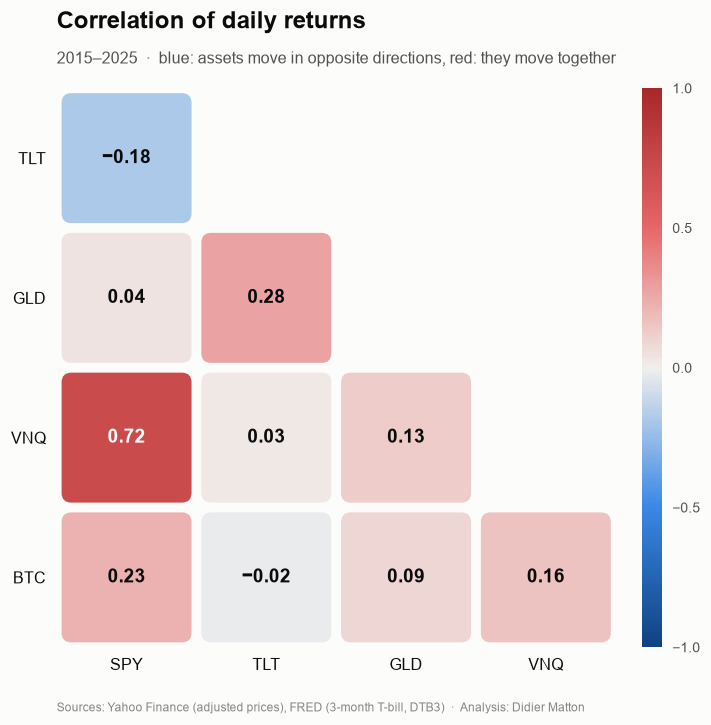

Variance (wᵀΣw)             : 0.029721
Variance (series)           : 0.029721
Identical                   : True
Portfolio volatility        : 17.24%
Average asset volatility    : 26.98%


In [5]:
# Step 2 — Execution

# 2.1 Returns
returns = compute_returns(prices)
rf_mean = rf_annual.loc[returns.index].mean()           # average annual risk-free rate

# 2.2 Statistics per asset
asset_stats = asset_statistics(returns, rf_mean)
display(asset_stats.style.format({
    "Annual return": "{:.2%}", "Annual volatility": "{:.2%}",
    "Cumulative return": "{:.0%}", "Worst day": "{:.2%}", "Sharpe ratio": "{:.2f}",
}))

# 2.3 Correlations
plot_correlation_matrix(returns, path="assets/correlation_matrix.png")
plt.show()

# 2.4 Variance of the equal-weight portfolio: matrix formula vs return series
w_eq = pd.Series(1 / len(TICKERS), index=TICKERS)
cov_annual = returns.cov() * TRADING_DAYS

var_matrix = portfolio_variance(w_eq, cov_annual)
var_series = portfolio_returns(w_eq, returns).var() * TRADING_DAYS

print(f"Variance (wᵀΣw)             : {var_matrix:.6f}")
print(f"Variance (series)           : {var_series:.6f}")
print(f"Identical                   : {np.isclose(var_matrix, var_series)}")
print(f"Portfolio volatility        : {np.sqrt(var_matrix):.2%}")
print(f"Average asset volatility    : {asset_stats['Annual volatility'].mean():.2%}")

**Statistics per asset (2015–2025)**

| Asset | Return | Volatility | Sharpe | Reading |
|---|---|---|---|---|
| BTC-USD | 73.8% | 66.8% | 1.07 | Best Sharpe ratio, with four times the volatility of the other assets |
| GLD | 12.4% | 14.8% | 0.71 | As efficient as equities with less risk, helped by the 2024–2025 gold rally |
| SPY | 14.2% | 17.8% | 0.69 | The benchmark |
| VNQ | 6.8% | 20.5% | 0.23 | Riskier than SPY for half the return |
| TLT | 0.4% | 15.0% | −0.11 | Below the risk-free rate: the 2022 rate shock |

Bitcoin's 73.8% is an arithmetic mean. Its geometric growth rate is about 67% per year ($277.8^{1/11} - 1$, from a cumulative return of +27,678%): the gap is volatility drag on compounding.

**Correlations.** SPY/VNQ (0.72) is the only strongly correlated pair: both are exposures to US equities. SPY/TLT (−0.18) shows that bonds partly offset equity losses over the full period. Gold is almost independent of everything (0.04 to 0.28), and Bitcoin has a correlation of at most 0.23 with the other assets.

**Diversification gain.** The equal-weight portfolio has a volatility of **17.24%**, against an average of 26.98% for its assets. It is even less volatile than SPY alone (17.79%) while holding 20% Bitcoin. These correlations are 11-year averages, however: in 2022, stocks and bonds fell together. The following sections test whether the optimal portfolios survive such episodes.

## 3. Efficient frontier

The frontier is built in two ways:
- **Simulation**: 20,000 long-only portfolios with weights drawn from a Dirichlet distribution (weights ≥ 0 that sum to 1). The concentration parameter α = 0.7 favours concentrated portfolios, which cover the edges of the cloud better. A fixed seed makes the results reproducible.
- **Optimization** (SLSQP): for each target return, the minimum-variance portfolio reaching it exactly. These portfolios form the efficient frontier.

Simulated weights are stored in one column per asset, so every portfolio can be read and filtered directly.

In [6]:
# Step 3 — Functions: efficient frontier


def portfolio_performance(weights: pd.Series, mean_returns: pd.Series, cov: pd.DataFrame, rf: float) -> tuple:
    """Annualized expected return, volatility and Sharpe ratio of a portfolio."""
    ret = float(weights @ mean_returns)
    vol = float(np.sqrt(weights @ cov @ weights))
    return ret, vol, (ret - rf) / vol


def simulate_portfolios(mean_returns: pd.Series, cov: pd.DataFrame, rf: float,
                        n: int = 20_000, alpha: float = 0.7, seed: int = 42) -> pd.DataFrame:
    """
    Simulate n portfolios with weights drawn from a Dirichlet distribution (w ≥ 0, sum = 1).

    alpha < 1 favours concentrated portfolios, which cover the edges of the cloud better.
    Returns one row per portfolio: one column per asset + Return, Volatility, Sharpe.
    """
    rng = np.random.default_rng(seed)
    W = rng.dirichlet(np.full(len(mean_returns), alpha), size=n)

    rets = W @ mean_returns.values
    vols = np.sqrt(np.einsum("ij,jk,ik->i", W, cov.values, W))   # wᵀΣw for every row in one operation

    sim = pd.DataFrame(W, columns=mean_returns.index)
    sim["Return"] = rets
    sim["Volatility"] = vols
    sim["Sharpe"] = (rets - rf) / vols
    return sim


def _clean_weights(w: np.ndarray, index: pd.Index) -> pd.Series:
    """Remove numerical residues of the optimizer (e.g. 1e-17) and rescale to a sum of 1."""
    w = np.where(w < 1e-6, 0.0, w)
    return pd.Series(w / w.sum(), index=index)


def _optimize_variance(cov: pd.DataFrame, constraints: list) -> np.ndarray:
    """Minimize the variance wᵀΣw under constraints, long-only (0 ≤ w ≤ 1)."""
    n = len(cov)
    result = minimize(
        lambda w: w @ cov.values @ w,
        x0=np.full(n, 1 / n),
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints=constraints,
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")
    return result.x


def min_variance_portfolio(cov: pd.DataFrame) -> pd.Series:
    """Minimum-variance portfolio (constraint: weights sum to 1)."""
    constraints = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    return _clean_weights(_optimize_variance(cov, constraints), cov.index)


def efficient_portfolio(mean_returns: pd.Series, cov: pd.DataFrame, target_return: float) -> pd.Series:
    """Minimum-variance portfolio reaching exactly a target return."""
    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1},
        {"type": "eq", "fun": lambda w: w @ mean_returns.values - target_return},
    ]
    return pd.Series(_optimize_variance(cov, constraints), index=cov.index)


def efficient_frontier(mean_returns: pd.Series, cov: pd.DataFrame, n_points: int = 60) -> pd.DataFrame:
    """
    Points of the efficient frontier, from the minimum-variance portfolio to the highest-return asset.

    The last target is slightly below the maximum return so that the optimization stays feasible.
    Returns one row per point: one column per asset + Return, Volatility.
    """
    w_min = min_variance_portfolio(cov)
    targets = np.linspace(float(w_min @ mean_returns), mean_returns.max() * 0.999, n_points)

    rows = []
    for target in targets:
        w = efficient_portfolio(mean_returns, cov, target)
        row = w.to_dict()
        row["Return"] = float(w @ mean_returns)
        row["Volatility"] = float(np.sqrt(w @ cov @ w))
        rows.append(row)
    return pd.DataFrame(rows)


def _plot_assets(ax, asset_stats: pd.DataFrame, label_offsets: dict | None) -> None:
    """Individual assets as dark dots with a surface ring and a bold label."""
    offsets = {"BTC-USD": (-10, 6, "right"), "GLD": (-10, 6, "right")}
    offsets.update(label_offsets or {})
    ax.scatter(asset_stats["Annual volatility"], asset_stats["Annual return"], s=58, color=THEME["ink_2"],
               edgecolor=THEME["surface"], linewidth=2, zorder=6)
    for ticker, row in asset_stats.iterrows():
        dx, dy, ha = offsets.get(ticker, (9, 4, "left"))
        label(ax, short(ticker), (row["Annual volatility"], row["Annual return"]), (dx, dy), ha=ha,
              size=10, weight=SEMIBOLD, z=7)


def plot_efficient_frontier(sim: pd.DataFrame, frontier: pd.DataFrame, asset_stats: pd.DataFrame,
                            label_offsets: dict | None = None, path: str | None = None):
    """Simulated portfolios (coloured by Sharpe), efficient frontier, minimum variance and assets."""
    fig, ax = plt.subplots(figsize=(11, 6.8))
    cloud = ax.scatter(sim["Volatility"], sim["Return"], c=sim["Sharpe"], cmap=SEQUENTIAL_BLUE,
                       s=5, alpha=0.8, linewidths=0, rasterized=True, zorder=1)
    ax.plot(frontier["Volatility"], frontier["Return"], color=THEME["ink"], linewidth=2.2, zorder=4)

    mv = frontier.iloc[0]
    ax.scatter(mv["Volatility"], mv["Return"], s=95, color=PORTFOLIO_COLORS["Minimum variance"],
               edgecolor=THEME["surface"], linewidth=2.2, zorder=6)
    label(ax, f"Minimum variance\n{fmt_pct(mv['Volatility'])} vol  ·  {fmt_pct(mv['Return'])} return",
          (mv["Volatility"], mv["Return"]), (0, -12), ha="center", va="top", size=9, z=8)
    _plot_assets(ax, asset_stats, label_offsets)

    ax.set_xlim(0, asset_stats["Annual volatility"].max() * 1.06)
    pct_axis(ax.xaxis)
    pct_axis(ax.yaxis)
    ax.grid(axis="x")
    ax.set_xlabel("Annualized volatility")
    ax.set_ylabel("Expected annual return")

    cbar = fig.colorbar(cloud, ax=ax, fraction=0.025, pad=0.02, aspect=32)
    cbar.solids.set_alpha(1)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, labelsize=9, colors=THEME["ink_2"])
    cbar.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt_num(v, 1)))
    cbar.set_label("Sharpe ratio of simulated portfolios", color=THEME["ink_2"], fontsize=9.5, labelpad=8)

    legend_row(ax, [dot("#3987e5", 6), Line2D([], [], color=THEME["ink"], lw=2.2),
                    dot(PORTFOLIO_COLORS["Minimum variance"]), dot(THEME["ink_2"])],
               [f"Simulated portfolios ({len(sim):,})", "Efficient frontier (SLSQP)",
                "Minimum-variance portfolio", "Individual assets"])
    add_header(ax, "The efficient frontier",
               "Random long-only portfolios against the frontier found by optimization  ·  2015–2025",
               top_pad=22)
    add_source(ax, offset=-50)
    save_figure(fig, path)
    return fig

Minimum-variance portfolio:


,Weight
Ticker,
SPY,33.1%
TLT,38.9%
GLD,28.0%
VNQ,0.0%
BTC-USD,0.0%


Return: 8.34% | Volatility: 9.43% | Sharpe: 0.67


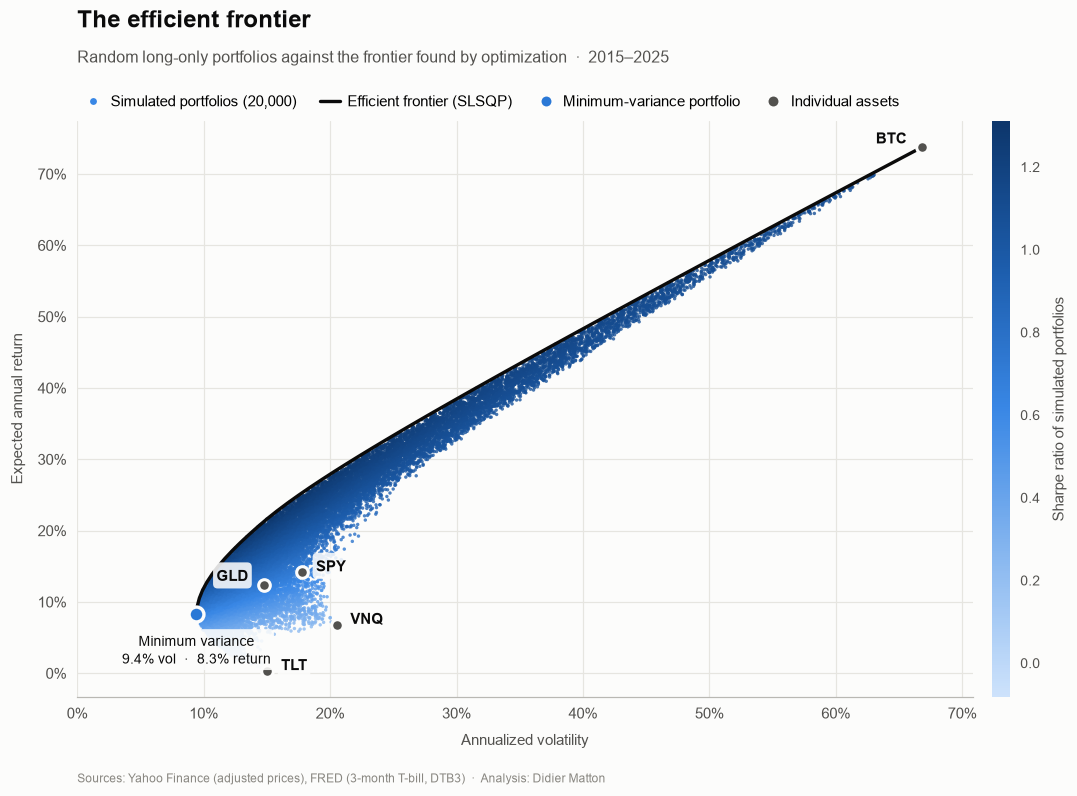

In [7]:
# Step 3 — Execution

mean_returns = returns.mean() * TRADING_DAYS      # annualized expected returns (arithmetic mean)
# cov_annual and rf_mean come from step 2

# 3.1 Simulation of 20,000 portfolios
sim = simulate_portfolios(mean_returns, cov_annual, rf_mean)

# 3.2 Efficient frontier by optimization
w_minvar = min_variance_portfolio(cov_annual)
frontier = efficient_frontier(mean_returns, cov_annual)

ret, vol, sharpe = portfolio_performance(w_minvar, mean_returns, cov_annual, rf_mean)
print("Minimum-variance portfolio:")
display(w_minvar.to_frame("Weight").style.format("{:.1%}"))
print(f"Return: {ret:.2%} | Volatility: {vol:.2%} | Sharpe: {sharpe:.2f}")

# 3.3 Chart
plot_efficient_frontier(sim, frontier, asset_stats, path="assets/efficient_frontier.png")
plt.show()

**Minimum-variance portfolio**

| SPY | TLT | GLD | VNQ | BTC-USD | Return | Volatility | Sharpe |
|---|---|---|---|---|---|---|---|
| 33.1% | 38.9% | 28.0% | 0% | 0% | 8.34% | 9.43% | 0.67 |

It combines the three least correlated assets: equities, bonds and gold. VNQ (too correlated with SPY and more volatile) and Bitcoin (far too volatile) are excluded. Its volatility of 9.4% is a third lower than that of the least risky asset taken alone (GLD, 14.8%): diversification in its clearest form.

**Shape of the frontier.** At the bottom left it is strongly curved: a lot of return is gained for little extra risk by adding SPY and some Bitcoin. Beyond about 25% volatility it becomes almost a straight line up to Bitcoin, because the optimizer is now only mixing Bitcoin with a diversified portfolio. Many simulated portfolios have a Sharpe ratio above Bitcoin's 1.07: diversified mixes beat the best single asset. TLT, VNQ and even SPY sit well below the frontier: on their own, they are inefficient choices.

## 4. Tangency portfolio and capital market line

The tangency portfolio maximizes the Sharpe ratio $\dfrac{r_p - r_f}{\sigma_p}$. SciPy only minimizes, so the negative Sharpe ratio is minimized, with the actual average T-bill rate as $r_f$.

The **capital market line** (CML) $r = r_f + S_T \cdot \sigma$ starts from the risk-free asset (at $\sigma = 0$) and touches the frontier at the tangency portfolio. Any combination of the risk-free asset and the tangency portfolio lies on this line.

In [8]:
# Step 4 — Functions: tangency portfolio and capital market line


def tangency_portfolio(mean_returns: pd.Series, cov: pd.DataFrame, rf: float) -> pd.Series:
    """
    Tangency portfolio: maximizes the Sharpe ratio (r_p − r_f) / σ_p, long-only.

    The negative Sharpe ratio is minimized, since SciPy can only minimize.
    """
    n = len(cov)

    def negative_sharpe(w):
        ret = w @ mean_returns.values
        vol = np.sqrt(w @ cov.values @ w)
        return -(ret - rf) / vol

    result = minimize(
        negative_sharpe,
        x0=np.full(n, 1 / n),
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")
    return _clean_weights(result.x, cov.index)


def capital_market_line(rf: float, sharpe_tangent: float, max_vol: float, n_points: int = 100) -> pd.DataFrame:
    """Capital market line: r = r_f + S_T × σ, for σ from 0 to max_vol."""
    sigmas = np.linspace(0, max_vol, n_points)
    return pd.DataFrame({"Volatility": sigmas, "Return": rf + sharpe_tangent * sigmas})


def portfolios_summary(portfolios: dict, mean_returns: pd.Series, cov: pd.DataFrame, rf: float) -> pd.DataFrame:
    """
    Summary table of several portfolios: weights + return, volatility, Sharpe.

    `portfolios`: dictionary {name: pd.Series of weights}.
    """
    rows = {}
    for name, w in portfolios.items():
        ret, vol, sharpe = portfolio_performance(w, mean_returns, cov, rf)
        rows[name] = {**w.to_dict(), "Return": ret, "Volatility": vol, "Sharpe": sharpe}
    return pd.DataFrame(rows).T


def plot_frontier_with_cml(sim: pd.DataFrame, frontier: pd.DataFrame, cml: pd.DataFrame, portfolios: dict,
                           mean_returns: pd.Series, cov: pd.DataFrame, rf: float, asset_stats: pd.DataFrame,
                           diluted: tuple | None = None, label_offsets: dict | None = None,
                           path: str | None = None):
    """
    Efficient frontier + CML + risk-free asset (σ = 0) + the three portfolios of the study.

    `portfolios`: {name: weights}, names as in PORTFOLIO_COLORS.
    `diluted`: optional (volatility, return) of the tangency portfolio mixed with T-bills,
    drawn on the CML above the minimum-variance portfolio (same risk, higher return).
    """
    perf = {name: portfolio_performance(w, mean_returns, cov, rf) for name, w in portfolios.items()}
    fig, ax = plt.subplots(figsize=(11, 6.8))

    ax.scatter(sim["Volatility"], sim["Return"], s=5, color=THEME["cloud"], linewidths=0,
               rasterized=True, zorder=1)
    ax.plot(frontier["Volatility"], frontier["Return"], color=THEME["ink"], linewidth=2.2, zorder=3)
    ax.plot(cml["Volatility"], cml["Return"], color=PORTFOLIO_COLORS["Tangency"], linewidth=1.8, zorder=4)

    # Risk-free asset, at σ = 0 (starting point of the CML)
    ax.scatter(0, rf, s=90, marker="D", color=THEME["ink"], edgecolor=THEME["surface"], linewidth=2,
               zorder=8, clip_on=False)
    label(ax, f"Risk-free rate {fmt_pct(rf, 2)}", (0, rf), (10, -12), size=9, color=THEME["ink_2"])

    # Portfolios: star for the tangency portfolio, dots for the other two
    label_pos = {"Tangency": (-14, 10, "right"), "Minimum variance": (0, -16, "center"),
                 "Equal weight": (12, -10, "left")}
    for name, (r, v, _) in perf.items():
        is_tangent = name == "Tangency"
        ax.scatter(v, r, s=330 if is_tangent else 95, marker="*" if is_tangent else "o",
                   color=PORTFOLIO_COLORS[name], edgecolor=THEME["surface"], linewidth=1.8, zorder=9)
        dx, dy, ha = label_pos.get(name, (10, 0, "left"))
        label(ax, name, (v, r), (dx, dy), ha=ha, va="top" if ha == "center" else "center",
              weight=SEMIBOLD, z=10)
    _plot_assets(ax, asset_stats, label_offsets)

    if diluted:
        v_d, r_d = diluted
        r_mv = perf["Minimum variance"][0]
        ax.plot([v_d, v_d], [r_mv, r_d], color=THEME["muted"], linewidth=1, linestyle=(0, (2, 2)), zorder=5)
        ax.scatter(v_d, r_d, s=95, color=PORTFOLIO_COLORS["Diluted tangency"], edgecolor=THEME["surface"],
                   linewidth=2, zorder=9)
        label(ax, "Tangency\n+ T-bills", (v_d, r_d), (-12, 4), ha="right", size=9, weight=SEMIBOLD, z=10)

    ax.set_xlim(-0.012, asset_stats["Annual volatility"].max() * 1.06)
    ax.set_ylim(min(0, asset_stats["Annual return"].min()) - 0.03, cml["Return"].max() * 1.02)
    pct_axis(ax.xaxis)
    pct_axis(ax.yaxis)
    ax.grid(axis="x")
    ax.set_xlabel("Annualized volatility")
    ax.set_ylabel("Expected annual return")

    legend_row(ax, [Line2D([], [], color=THEME["ink"], lw=2.2),
                    Line2D([], [], color=PORTFOLIO_COLORS["Tangency"], lw=1.8),
                    Line2D([], [], marker="D", linestyle="none", markersize=7, markerfacecolor=THEME["ink"],
                           markeredgewidth=0),
                    dot(THEME["cloud"], 6), dot(THEME["ink_2"])],
               ["Efficient frontier", "Capital market line", "Risk-free asset", "Simulated portfolios",
                "Individual assets"])

    r_t, v_t, s_t = perf["Tangency"]
    w_t = portfolios["Tangency"].sort_values(ascending=False)
    mix = "  ·  ".join(f"{short(t)} {fmt_pct(w, 0)}" for t, w in w_t.items() if w > 0.005)
    add_card(ax, "TANGENCY PORTFOLIO",
             f"Sharpe ratio  {fmt_num(s_t, 2)}\nReturn  {fmt_pct(r_t)}   ·   Volatility  {fmt_pct(v_t)}\n{mix}",
             accent=PORTFOLIO_COLORS["Tangency"])
    add_header(ax, "Capital market line and tangency portfolio",
               "The CML starts at the risk-free rate and touches the frontier at the maximum-Sharpe portfolio"
               + ("  ·  light orange: tangency + T-bills at the minimum-variance volatility" if diluted else ""),
               top_pad=22)
    add_source(ax, offset=-50)
    save_figure(fig, path)
    return fig

Same volatility as minimum variance: 57.7% tangency + 42.3% T-bills → expected return 14.39% vs 8.34%


,SPY,TLT,GLD,VNQ,BTC-USD,Return,Volatility,Sharpe
Tangency,31.7%,0.0%,51.3%,0.0%,17.1%,23.5%,16.3%,1.32
Minimum variance,33.1%,38.9%,28.0%,0.0%,0.0%,8.3%,9.4%,0.67
Equal weight,20.0%,20.0%,20.0%,20.0%,20.0%,21.5%,17.2%,1.13


Best simulated Sharpe: 1.3115 | Tangency Sharpe: 1.3160


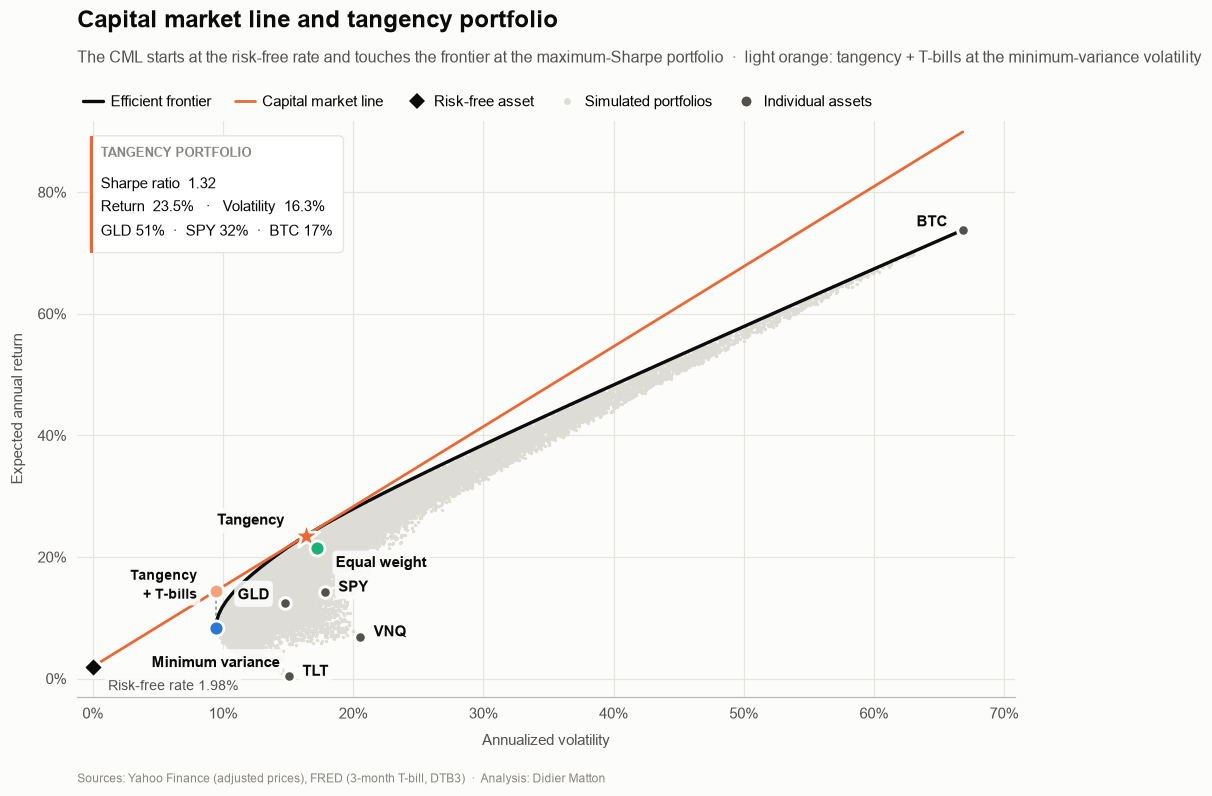

In [9]:
# Step 4 — Execution

# 4.1 Tangency portfolio
w_tangent = tangency_portfolio(mean_returns, cov_annual, rf_mean)
perf_tangent = portfolio_performance(w_tangent, mean_returns, cov_annual, rf_mean)
perf_minvar = portfolio_performance(w_minvar, mean_returns, cov_annual, rf_mean)

# Point of the CML with the same volatility as the minimum-variance portfolio
k_dilute = perf_minvar[1] / perf_tangent[1]                 # share of tangency, the rest in T-bills
diluted_point = (perf_minvar[1], rf_mean + k_dilute * (perf_tangent[0] - rf_mean))
print(f"Same volatility as minimum variance: {k_dilute:.1%} tangency + {1 - k_dilute:.1%} T-bills "
      f"→ expected return {diluted_point[1]:.2%} vs {perf_minvar[0]:.2%}")

# 4.2 The three portfolios studied in the rest of the project
portfolios = {"Tangency": w_tangent, "Minimum variance": w_minvar, "Equal weight": w_eq}
summary = portfolios_summary(portfolios, mean_returns, cov_annual, rf_mean)
fmt = {col: "{:.1%}" for col in TICKERS + ["Return", "Volatility"]}
fmt["Sharpe"] = "{:.2f}"
display(summary.style.format(fmt))

# Check: no simulated portfolio may beat the tangency portfolio
print(f"Best simulated Sharpe: {sim['Sharpe'].max():.4f} | Tangency Sharpe: {perf_tangent[2]:.4f}")

# 4.3 Capital market line and chart
cml = capital_market_line(rf_mean, perf_tangent[2], max_vol=asset_stats["Annual volatility"].max())
plot_frontier_with_cml(sim, frontier, cml, portfolios, mean_returns, cov_annual, rf_mean, asset_stats,
                       diluted=diluted_point, path="assets/cml_tangency.png")
plt.show()

**The three portfolios of the study**

| | SPY | TLT | GLD | VNQ | BTC-USD | Return | Volatility | Sharpe |
|---|---|---|---|---|---|---|---|---|
| **Tangency** | 31.7% | 0% | **51.3%** | 0% | **17.1%** | 23.5% | 16.3% | **1.32** |
| **Minimum variance** | 33.1% | 38.9% | 28.0% | 0% | 0% | 8.3% | 9.4% | 0.67 |
| **Equal weight** | 20% | 20% | 20% | 20% | 20% | 21.5% | 17.2% | 1.13 |

The optimization is validated: the best of the 20,000 simulated portfolios reaches a Sharpe ratio of 1.3115, just below the tangency portfolio's 1.3160.

- **The tangency portfolio is concentrated**: more than half in gold, a direct effect of the 2024–2025 gold rally. The optimizer "sees" the past and overweights what worked best.
- **17% Bitcoin, but a much larger share of risk.** With 67% volatility, this small weight weighs heavily on total risk (measured in section 6).
- **The equal-weight portfolio comes close (Sharpe 1.13 vs 1.32) without any optimization.** Out of sample, the naive 1/N portfolio often beats optimized portfolios because it depends on no estimate (DeMiguel, Garlappi and Uppal, 2009).
- **TLT and VNQ are excluded**: TLT returned less than the risk-free rate, VNQ duplicates SPY.

**What the CML implies for the comparison.** The tangency and minimum-variance portfolios do not carry the same risk (16.3% vs 9.4% volatility). The CML shows how to compare them fairly: holding about 58% of the tangency portfolio and 42% of T-bills gives the same 9.4% volatility as the minimum-variance portfolio, with an expected return of about 14.4% instead of 8.3%. This "diluted tangency" portfolio is added to the downside-risk tests in section 6.

## 5. Weight instability and out-of-sample test

An optimal portfolio is only useful if it remains optimal after it is chosen. Two tests:
1. **Rolling windows**: the tangency portfolio is re-estimated on the trailing 3 years, every 6 months. If its weights swing from one window to the next, the "optimum" mostly reflects the estimation period.
2. **Out of sample**: the three portfolios are estimated on 2015–2021, then held unchanged over 2022–2025. Only this second period measures what an investor would actually have earned.

Portfolios are held at constant weights (implicit daily rebalancing, no transaction costs).

In [10]:
# Step 5 — Functions: tangency instability and out-of-sample test

def estimate_inputs(returns: pd.DataFrame, rf_annual: pd.Series, periods: int = TRADING_DAYS) -> tuple:
    """Annualized expected returns, covariance matrix and average risk-free rate over a sample."""
    mean_returns = returns.mean() * periods
    cov = returns.cov() * periods
    rf = rf_annual.loc[returns.index].mean()
    return mean_returns, cov, rf


def rolling_tangency_weights(returns: pd.DataFrame, rf_annual: pd.Series,
                             window_years: int = 3, step_months: int = 6,
                             periods: int = TRADING_DAYS) -> pd.DataFrame:
    """
    Re-estimate the tangency portfolio on rolling windows.

    Window of `window_years` years, shifted by `step_months` months at each estimation.
    Returns one row per window (indexed by its end date), one column per asset.
    """
    window = window_years * periods
    step = int(step_months / 12 * periods)
    rows = {}
    for end in range(window, len(returns) + 1, step):
        sample = returns.iloc[end - window:end]
        mean_returns, cov, rf = estimate_inputs(sample, rf_annual, periods)
        try:
            rows[sample.index[-1]] = tangency_portfolio(mean_returns, cov, rf)
        except RuntimeError:
            rows[sample.index[-1]] = pd.Series(np.nan, index=returns.columns)
    return pd.DataFrame(rows).T


def realized_performance(weights: pd.Series, returns: pd.DataFrame, rf: float,
                         periods: int = TRADING_DAYS) -> dict:
    """Realized performance of a constant-weight portfolio over a given period."""
    r = returns @ weights
    ann_ret = r.mean() * periods
    ann_vol = r.std() * np.sqrt(periods)
    return {"Return": ann_ret, "Volatility": ann_vol,
            "Sharpe": (ann_ret - rf) / ann_vol, "Cumulative return": (1 + r).prod() - 1}


def out_of_sample_test(returns: pd.DataFrame, rf_annual: pd.Series, split_date: str) -> tuple:
    """
    Estimate the three portfolios on the training period, then measure their realized performance afterwards.

    Returns: (comparison table, estimated weights, daily out-of-sample returns per portfolio).
    """
    train = returns.loc[:split_date]
    test = returns.loc[split_date:].iloc[1:]           # the split date belongs to the training period

    mu_train, cov_train, rf_train = estimate_inputs(train, rf_annual)
    rf_test = rf_annual.loc[test.index].mean()

    weights = {
        "Tangency": tangency_portfolio(mu_train, cov_train, rf_train),
        "Minimum variance": min_variance_portfolio(cov_train),
        "Equal weight": pd.Series(1 / returns.shape[1], index=returns.columns),
    }

    rows, test_returns = {}, {}
    for name, w in weights.items():
        _, _, sharpe_in = portfolio_performance(w, mu_train, cov_train, rf_train)
        perf_out = realized_performance(w, test, rf_test)
        rows[name] = {"Sharpe (train)": sharpe_in, **{f"{k} (test)": v for k, v in perf_out.items()}}
        test_returns[name] = test @ w

    return pd.DataFrame(rows).T, pd.DataFrame(weights).T, pd.DataFrame(test_returns)


def sharpe_standard_error(sharpe: float, years: float) -> float:
    """Approximate standard error of an annualized Sharpe ratio estimated on `years` years (Lo, 2002, i.i.d. returns)."""
    return float(np.sqrt((1 + sharpe**2 / 2) / years))


def oos_drawdown_summary(test_returns: pd.DataFrame, year: str = "2022") -> pd.DataFrame:
    """Lowest value of $1 during a given year and maximum drawdown over the whole test period."""
    growth = (1 + test_returns).cumprod()
    return pd.DataFrame({
        f"Lowest value of $1 in {year}": growth.loc[year].min(),
        "Max drawdown (test)": (growth / growth.cummax() - 1).min(),
    })


def plot_rolling_weights(weights: pd.DataFrame, path: str | None = None):
    """
    Stacked columns of the tangency weights, one column per estimation window.

    Columns (not areas): weights are constant between two re-estimations, so interpolating
    between them would show allocations that never existed.
    """
    w = weights.fillna(0)
    active = [t for t in w.columns if w[t].max() > 0.005]
    never = [short(t) for t in w.columns if t not in active]
    x = np.arange(len(w))

    fig, ax = plt.subplots(figsize=(11.5, 6.4))
    bottom = np.zeros(len(w))
    for ticker in active:
        values = w[ticker].values
        ax.bar(x, values, bottom=bottom, width=0.74, color=ASSET_COLORS[ticker],
               edgecolor=THEME["surface"], linewidth=1.6, zorder=2)
        for xi, v, b in zip(x, values, bottom):
            if v >= 0.10:
                ax.text(xi, b + v / 2, fmt_pct(v, 0), ha="center", va="center", fontsize=8,
                        fontweight=SEMIBOLD, color=text_color_for(ASSET_COLORS[ticker]), zorder=3)
        bottom += values

    ax.set_ylim(0, 1)
    ax.set_xlim(-0.6, len(w) - 0.4)
    ax.set_xticks(x, [f"{d:%b}\n{d:%Y}" for d in w.index])
    ax.tick_params(axis="x", labelsize=8.5)
    pct_axis(ax.yaxis)
    ax.set_xlabel("End of the 3-year estimation window")

    legend_row(ax, [swatch(ASSET_COLORS[t]) for t in active], [short(t) for t in active])
    subtitle = "Maximum-Sharpe weights re-estimated every 6 months on the trailing 3 years (long-only)"
    if never:
        subtitle += f"  ·  never selected: {', '.join(never)}"
    add_header(ax, "The \"optimal\" portfolio keeps changing", subtitle, top_pad=22)
    add_source(ax, offset=-62)
    save_figure(fig, path)
    return fig


def _spread(values: dict, min_gap: float) -> dict:
    """Vertical positions of end labels, pushed apart by at least `min_gap` (data units)."""
    order = sorted(values, key=values.get)
    pos, last = {}, -np.inf
    for name in order:
        pos[name] = max(values[name], last + min_gap)
        last = pos[name]
    return pos


def plot_oos_growth(test_returns: pd.DataFrame, path: str | None = None):
    """Growth of $1 invested in each portfolio over the out-of-sample period."""
    start = test_returns.index[0] - pd.offsets.BDay(1)
    growth = pd.concat([pd.DataFrame(1.0, index=[start], columns=test_returns.columns),
                        (1 + test_returns).cumprod()])

    fig, ax = plt.subplots(figsize=(11, 6))
    shock = (pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"))
    if growth.index[0] <= shock[1]:
        ax.axvspan(*shock, color=THEME["band"], lw=0, zorder=0)
        ax.annotate("2022: stocks and bonds fall together", xy=(shock[0], 1), xycoords=("data", "axes fraction"),
                    xytext=(8, -8), textcoords="offset points", va="top", fontsize=9, color=THEME["ink_2"])
    ax.axhline(1, color=THEME["baseline"], linewidth=1, zorder=1)

    for name in growth.columns:
        ax.plot(growth.index, growth[name], color=PORTFOLIO_COLORS[name], linewidth=2, zorder=3)
        ax.scatter(growth.index[-1], growth[name].iloc[-1], s=45, color=PORTFOLIO_COLORS[name],
                   edgecolor=THEME["surface"], linewidth=2, zorder=4)

    ymin, ymax = ax.get_ylim()
    positions = _spread(growth.iloc[-1].to_dict(), min_gap=0.055 * (ymax - ymin))
    for name, y in positions.items():
        ax.annotate(f"{name}  ${growth[name].iloc[-1]:.2f}", xy=(growth.index[-1], y), xytext=(12, 0),
                    textcoords="offset points", va="center", fontsize=9.5, color=THEME["ink"],
                    annotation_clip=False)

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:.2f}"))
    ax.set_xlim(growth.index[0], growth.index[-1])

    legend_row(ax, [Line2D([], [], color=PORTFOLIO_COLORS[n], lw=2.2) for n in growth.columns],
               list(growth.columns))
    add_header(ax, "Out of sample, the naive 1/N portfolio comes out ahead",
               "Value of $1 invested in January 2022  ·  weights estimated on 2015–2021, then held constant"
               "  ·  one 4-year split", top_pad=22)
    add_source(ax, offset=-34)
    save_figure(fig, path)
    return fig

Ticker,SPY,TLT,GLD,VNQ,BTC-USD
2018-01-03 00:00:00,51%,22%,10%,0%,17%
2018-07-05 00:00:00,48%,34%,3%,0%,14%
2019-01-04 00:00:00,44%,19%,25%,0%,12%
2019-07-08 00:00:00,69%,15%,0%,0%,16%
2020-01-06 00:00:00,42%,31%,22%,0%,6%
2020-07-07 00:00:00,24%,44%,25%,0%,6%
2021-01-05 00:00:00,27%,42%,25%,0%,5%
2021-07-07 00:00:00,33%,43%,16%,0%,9%
2022-01-04 00:00:00,39%,42%,8%,0%,12%
2022-07-07 00:00:00,33%,0%,54%,0%,13%


Range of the weights across windows:


Ticker,SPY,TLT,GLD,VNQ,BTC-USD
min,1%,0%,0%,0%,5%
max,82%,44%,79%,0%,37%


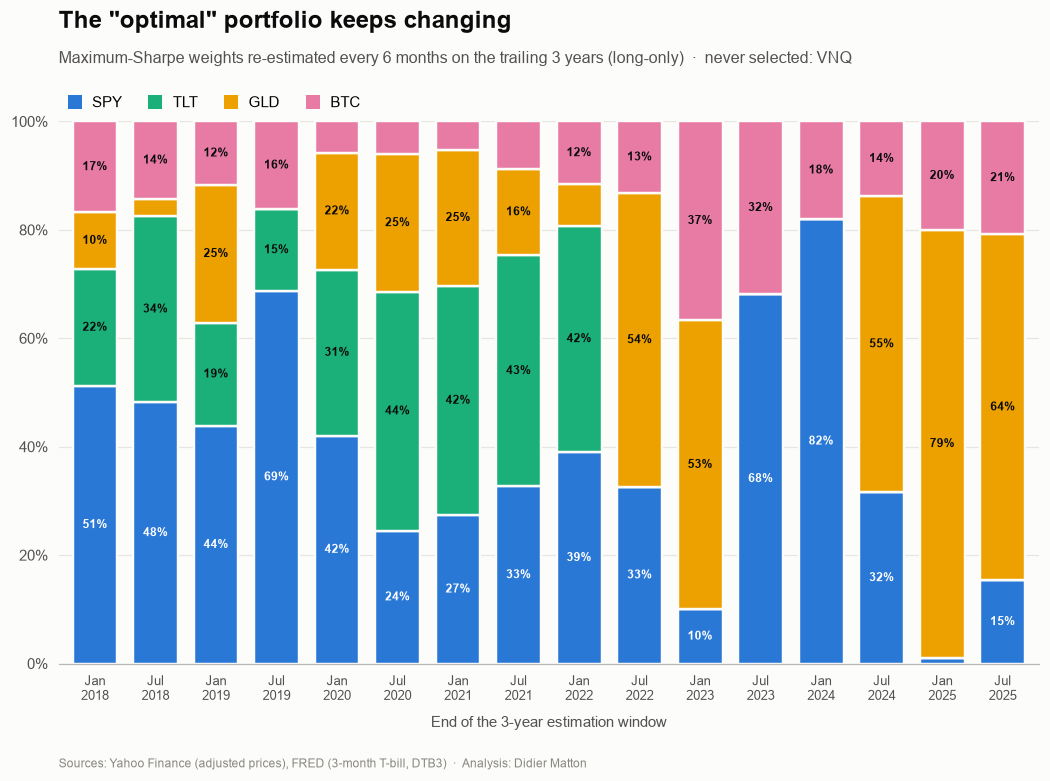

Weights estimated on 2015–2021:


Ticker,SPY,TLT,GLD,VNQ,BTC-USD
Tangency,41.1%,38.0%,7.5%,0.0%,13.4%
Minimum variance,34.8%,43.9%,21.3%,0.0%,0.0%
Equal weight,20.0%,20.0%,20.0%,20.0%,20.0%


Performance: training vs test


,Sharpe (train),Return (test),Volatility (test),Sharpe (test),Cumulative return (test),Std. error of Sharpe (test)
Tangency,1.61,7.48%,14.34%,0.24,29.3%,0.51
Minimum variance,1.02,5.30%,11.39%,0.11,20.3%,0.50
Equal weight,1.51,11.04%,16.36%,0.43,47.1%,0.52


Test period: 4.0 years
Depth of the fall out of sample:


,Lowest value of $1 in 2022,Max drawdown (test)
Tangency,$0.69,-30.8%
Minimum variance,$0.75,-24.4%
Equal weight,$0.68,-31.9%


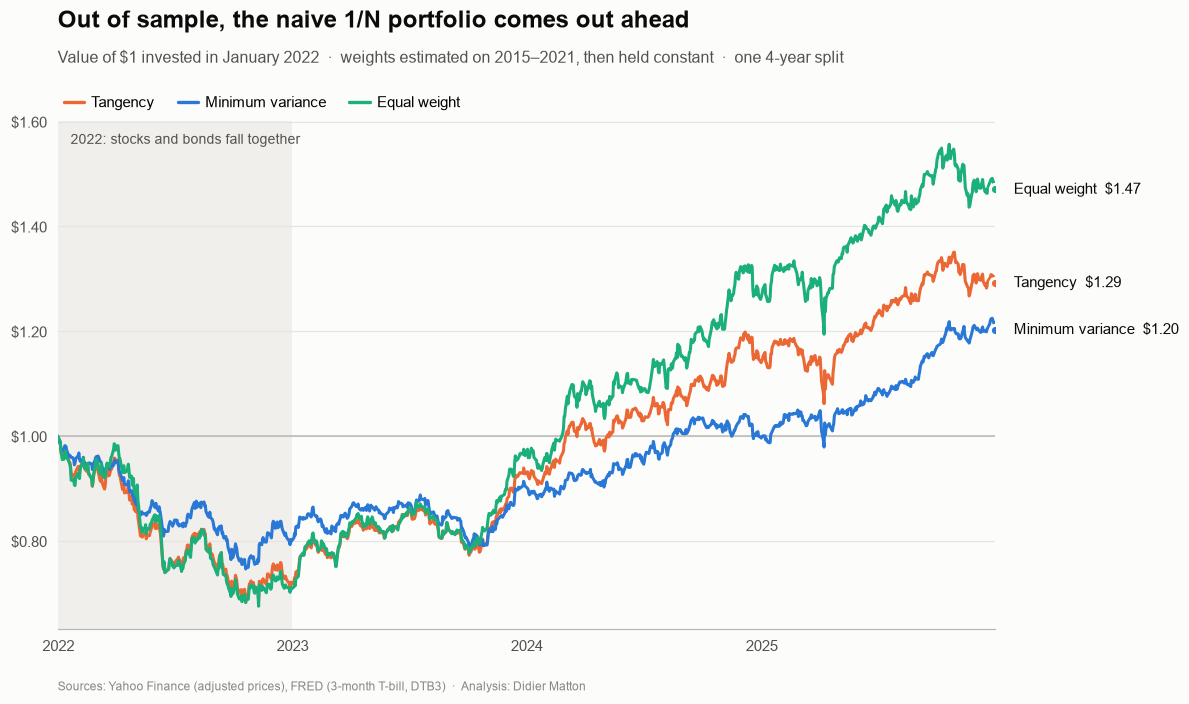

In [11]:
# Step 5 — Execution

# 5.1 Instability: tangency portfolio on 3-year rolling windows (6-month step)
rolling_w = rolling_tangency_weights(returns, rf_annual)
display(rolling_w.style.format("{:.0%}"))
print("Range of the weights across windows:")
display(rolling_w.agg(["min", "max"]).style.format("{:.0%}"))

plot_rolling_weights(rolling_w, path="assets/rolling_tangency_weights.png")
plt.show()

# 5.2 Out of sample: estimation on 2015–2021, test on 2022–2025
SPLIT_DATE = "2021-12-31"
oos_table, oos_weights, oos_returns = out_of_sample_test(returns, rf_annual, SPLIT_DATE)

# How precise is a Sharpe ratio measured on the test period?
years_test = len(oos_returns) / TRADING_DAYS
oos_table["Std. error of Sharpe (test)"] = [sharpe_standard_error(s, years_test) for s in oos_table["Sharpe (test)"]]

print("Weights estimated on 2015–2021:")
display(oos_weights.style.format("{:.1%}"))
print("Performance: training vs test")
display(oos_table.style.format({
    "Sharpe (train)": "{:.2f}", "Return (test)": "{:.2%}", "Volatility (test)": "{:.2%}",
    "Sharpe (test)": "{:.2f}", "Cumulative return (test)": "{:.1%}", "Std. error of Sharpe (test)": "{:.2f}",
}))
print(f"Test period: {years_test:.1f} years")

print("Depth of the fall out of sample:")
display(oos_drawdown_summary(oos_returns).style.format({"Lowest value of $1 in 2022": "${:.2f}",
                                                         "Max drawdown (test)": "{:.1%}"}))

plot_oos_growth(oos_returns, path="assets/oos_growth.png")
plt.show()

**Rolling windows: the optimum is unstable.** Across the 16 windows, SPY ranges from 1% to 82%, gold from 0% to 79%, and TLT drops abruptly from 42% to 0% in mid-2022, once the 3-year window includes the rate shock and negative bond returns. VNQ is never selected (dominated by SPY), while Bitcoin is always present, between 5% and 37%. This is the classic result of Chopra and Ziemba (1993): optimal weights are driven mainly by expected returns, the least precisely estimated input, and a small error on a mean shifts the weights a lot.

**Out of sample: the naive 1/N portfolio comes out ahead.**

| | Sharpe (2015–2021) | Sharpe (2022–2025) | Change | Growth of $1 |
|---|---|---|---|---|
| Tangency | 1.61 | 0.24 | −85% | $1.29 |
| Equal weight | 1.51 | **0.43** | −72% | **$1.47** |
| Minimum variance | 1.02 | 0.11 | −89% | $1.20 |

- The estimated tangency portfolio held 38% TLT and the minimum-variance portfolio 44%. Over 2015–2021, long bonds paid off and hedged equity losses; in 2022 stocks and bonds fell together and TLT lost close to a third of its value. Both optimized portfolios relied on a relationship that broke.
- Test Sharpe ratios are also depressed by the risk-free rate, which rose from about 1% to about 4% on average over 2022–2025.
- During 2022, the minimum-variance portfolio fell the least (lowest value of $1: $0.75, vs $0.69 for tangency and $0.68 for equal weight), yet it finished last. Resisting a fall and earning the most are two different things: section 6 measures the first one.
- **These differences are not statistically significant.** Over a 4-year test, the standard error of a Sharpe ratio is about 0.5: the gap between 0.43, 0.24 and 0.11 is well within estimation noise, and it comes from a single split. The result is consistent with the literature on 1/N (DeMiguel, Garlappi and Uppal, 2009), but it does not prove it on its own.

## 6. Downside risk

Four portfolios are compared on what happens on bad days: the three portfolios of sections 3–4 (estimated on the full sample) and the **diluted tangency** portfolio, about 58% tangency and 42% T-bills, which has the **same volatility as the minimum-variance portfolio**. Comparing the tangency portfolio alone with the minimum-variance portfolio mixes two questions, because the minimum-variance portfolio is the least volatile by construction. The diluted version isolates the real one: at equal risk, which portfolio loses less when markets fall?

- **VaR (value at risk)** at level α: the daily loss that is exceeded only (1 − α) of the time.
- **CVaR (conditional VaR, or expected shortfall)**: the average loss *beyond* the VaR, that is the average of the worst days. It is the measure that answers the research question.

Four estimation methods are compared:
| Method | Assumption |
|---|---|
| Historical | The empirical distribution of past returns |
| Normal | Returns follow a normal distribution (mean, standard deviation) |
| Student t | Fat-tailed distribution fitted by maximum likelihood |
| Monte Carlo (t) | 100,000 simulated days from a multivariate Student t (ν = 5) that keeps the observed covariance |

Then: actual losses during two crises (Covid crash and 2022), drawdowns, and the contribution of each asset to the tangency portfolio's risk.

In [12]:
# Step 6 — Functions: downside risk (VaR, CVaR, stress tests, contributions)

METHODS = ["Historical", "Normal", "Student t", "Monte Carlo (t)"]


def exposure_for_volatility(weights: pd.Series, cov: pd.DataFrame, target_vol: float) -> float:
    """Share of a portfolio to hold (the rest in T-bills) to reach a target annual volatility."""
    return target_vol / np.sqrt(portfolio_variance(weights, cov))


def portfolio_return_series(portfolios: dict, returns: pd.DataFrame, rf_annual: pd.Series | None = None,
                            exposure: dict | None = None) -> pd.DataFrame:
    """
    Daily returns of each portfolio (one column per portfolio).

    `exposure` {name: k} mixes a portfolio with T-bills: k × portfolio + (1 − k) × daily risk-free rate.
    k = 1 (default) is the portfolio alone; k < 1 is a point of the CML between the risk-free asset and it.
    """
    exposure = exposure or {}
    rf_daily = 0.0 if rf_annual is None else rf_annual.loc[returns.index] / TRADING_DAYS
    series = {}
    for name, w in portfolios.items():
        k = exposure.get(name, 1.0)
        series[name] = k * (returns @ w[returns.columns]) + (1 - k) * rf_daily
    return pd.DataFrame(series)


def var_cvar_historical(r: pd.Series, alpha: float = 0.99) -> tuple[float, float]:
    """Historical VaR and CVaR, expressed as positive losses."""
    q = r.quantile(1 - alpha)
    return -q, -r[r <= q].mean()


def var_cvar_normal(r: pd.Series, alpha: float = 0.99) -> tuple[float, float]:
    """VaR and CVaR assuming normally distributed returns."""
    mu, sigma = r.mean(), r.std()
    z = stats.norm.ppf(1 - alpha)
    return -(mu + sigma * z), -mu + sigma * stats.norm.pdf(z) / (1 - alpha)


def var_cvar_student(r: pd.Series, alpha: float = 0.99) -> tuple[float, float]:
    """
    VaR and CVaR under a Student t distribution fitted by maximum likelihood.

    stats.t.fit returns the scale parameter directly: the sqrt((nu-2)/nu) factor is only
    needed when starting from the sample standard deviation.
    """
    nu, loc, scale = stats.t.fit(r)
    p = 1 - alpha
    q = stats.t.ppf(p, nu)
    es_std = (nu + q**2) / (nu - 1) * stats.t.pdf(q, nu) / p     # CVaR of the standard Student t
    return -(loc + scale * q), -loc + scale * es_std


def var_cvar_monte_carlo(weights: pd.Series, returns: pd.DataFrame, alpha: float = 0.99,
                         nu: float = 5, n_sims: int = 100_000, seed: int = 42,
                         exposure: float = 1.0, rf_daily: float = 0.0) -> tuple[float, float]:
    """
    VaR and CVaR from a multivariate Student t simulation of the assets.

    Keeps the observed covariance between assets and adds common fat tails
    (a shock hits all assets at the same time). Same seed for every portfolio.
    `exposure` and `rf_daily` handle a portfolio mixed with T-bills.
    """
    rng = np.random.default_rng(seed)
    mu = returns.mean().values
    chol = np.linalg.cholesky(returns.cov().values)
    z = rng.standard_normal((n_sims, len(mu))) @ chol.T
    chi = rng.chisquare(nu, size=(n_sims, 1))
    sims = mu + z * np.sqrt((nu - 2) / chi)                     # same variance as the observed covariance
    sim_p = exposure * (sims @ weights[returns.columns].values) + (1 - exposure) * rf_daily
    return var_cvar_historical(pd.Series(sim_p), alpha)


def risk_table(portfolios: dict, returns: pd.DataFrame, rf_annual: pd.Series | None = None,
               exposure: dict | None = None, alphas: tuple = (0.95, 0.99), nu: float = 5) -> pd.DataFrame:
    """VaR / CVaR table: one row per (portfolio, level), one column per (measure, method)."""
    exposure = exposure or {}
    port_r = portfolio_return_series(portfolios, returns, rf_annual, exposure)
    rf_daily = 0.0 if rf_annual is None else rf_annual.loc[returns.index].mean() / TRADING_DAYS
    rows = []
    for name, w in portfolios.items():
        for alpha in alphas:
            results = {
                "Historical": var_cvar_historical(port_r[name], alpha),
                "Normal": var_cvar_normal(port_r[name], alpha),
                "Student t": var_cvar_student(port_r[name], alpha),
                "Monte Carlo (t)": var_cvar_monte_carlo(w, returns, alpha, nu,
                                                        exposure=exposure.get(name, 1.0), rf_daily=rf_daily),
            }
            for method, (var, cvar) in results.items():
                rows.append({"Portfolio": name, "Level": f"{alpha:.0%}", "Method": method, "VaR": var, "CVaR": cvar})
    table = pd.DataFrame(rows).pivot_table(index=["Portfolio", "Level"], columns="Method", values=["VaR", "CVaR"])
    return table.reindex(columns=pd.MultiIndex.from_product([["VaR", "CVaR"], METHODS]))


def tail_statistics(port_r: pd.DataFrame) -> pd.DataFrame:
    """Skewness, excess kurtosis and degrees of freedom of the fitted Student t."""
    return pd.DataFrame({
        "Skewness": port_r.skew(),
        "Excess kurtosis": port_r.kurt(),
        "nu (Student t)": {c: stats.t.fit(port_r[c])[0] for c in port_r},
    })


def drawdown_series(r: pd.Series) -> pd.Series:
    """Decline of the portfolio value from its running peak."""
    wealth = (1 + r).cumprod()
    return wealth / wealth.cummax() - 1


def risk_profile(port_r: pd.DataFrame, rf_annual: pd.Series, alpha: float = 0.99,
                 periods: int = TRADING_DAYS) -> pd.DataFrame:
    """
    Return, volatility, Sharpe, historical CVaR, CVaR per unit of daily volatility and maximum drawdown.

    CVaR / daily volatility measures the shape of the tail independently of the level of risk:
    a normal distribution gives 2.67 at 99%.
    """
    rf = rf_annual.loc[port_r.index].mean()
    rows = {}
    for name in port_r:
        r = port_r[name]
        ann_ret, daily_vol = r.mean() * periods, r.std()
        cvar = var_cvar_historical(r, alpha)[1]
        rows[name] = {"Return": ann_ret, "Volatility": daily_vol * np.sqrt(periods),
                      "Sharpe": (ann_ret - rf) / (daily_vol * np.sqrt(periods)),
                      f"CVaR {alpha:.0%}": cvar, "CVaR / daily vol": cvar / daily_vol,
                      "Max drawdown": drawdown_series(r).min()}
    return pd.DataFrame(rows).T


def stress_table(port_r: pd.DataFrame, periods: dict) -> pd.DataFrame:
    """Cumulative return over crisis periods, worst day and maximum drawdown."""
    rows = {}
    for name in port_r:
        r = port_r[name]
        row = {label: (1 + r.loc[start:end]).prod() - 1 for label, (start, end) in periods.items()}
        row["Worst day"] = r.min()
        row["Max drawdown"] = drawdown_series(r).min()
        rows[name] = row
    return pd.DataFrame(rows).T


def risk_contributions(weights: pd.Series, returns: pd.DataFrame, cov: pd.DataFrame, alpha: float = 0.99) -> pd.DataFrame:
    """
    Share of each asset in the portfolio's risk.

    Variance: w_i (Σw)_i / wᵀΣw.  CVaR: share of each asset in the average loss of the worst days.
    """
    w = weights[returns.columns]
    var_contrib = w * (cov @ w) / portfolio_variance(w, cov)
    r_p = returns @ w
    tail = r_p <= r_p.quantile(1 - alpha)
    tail_loss = -(returns[tail] * w).mean()
    return pd.DataFrame({"Weight": w, "Variance contribution": var_contrib,
                         f"CVaR {alpha:.0%} contribution": tail_loss / tail_loss.sum()})


def plot_cvar_comparison(table: pd.DataFrame, level: str = "99%", path: str | None = None):
    """Dot plot: CVaR of each portfolio under the four methods (one row per method)."""
    cvar = table["CVaR"].xs(level, level="Level")
    data = cvar.loc[[n for n in PORTFOLIO_COLORS if n in cvar.index], METHODS]
    y = np.arange(len(METHODS))[::-1]
    x_max = data.values.max() * 1.15

    fig, ax = plt.subplots(figsize=(11, 5.6))
    ax.axhspan(y[0] - 0.42, y[0] + 0.42, color=THEME["band"], lw=0, zorder=0)    # observed reference
    for yi, method in zip(y, METHODS):
        values = data[method].sort_values()
        ax.plot([values.min(), values.max()], [yi, yi], color=THEME["grid"], linewidth=5, zorder=1)
        last_above = -np.inf
        for name, v in values.items():
            ax.scatter(v, yi, s=125, color=PORTFOLIO_COLORS[name], edgecolor=THEME["surface"],
                       linewidth=2.2, zorder=3)
            above = v - last_above > 0.07 * x_max
            ax.annotate(fmt_pct(v, 1), (v, yi), xytext=(0, 12 if above else -13), textcoords="offset points",
                        ha="center", va="center", fontsize=8.5, color=THEME["ink_2"], zorder=4)
            if above:
                last_above = v

    ax.set_yticks(y, ["Historical (observed)" if m == "Historical" else m for m in METHODS])
    ax.tick_params(axis="y", labelsize=10, labelcolor=THEME["ink"])
    ax.set_ylim(y[-1] - 0.6, y[0] + 0.6)
    ax.set_xlim(0, x_max)
    pct_axis(ax.xaxis, 1)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x")
    ax.set_xlabel(f"Average loss on the worst {1 - float(level.strip('%')) / 100:.0%} of days (daily CVaR {level})")

    hist = data["Historical"]
    if "Diluted tangency" in hist:
        subtitle = (f"Alone, the tangency portfolio loses {hist['Tangency'] / hist['Minimum variance']:.1f}× as much "
                    f"as minimum variance; at the same volatility, {fmt_pct(hist['Diluted tangency'], 2)} "
                    f"vs {fmt_pct(hist['Minimum variance'], 2)}")
    else:
        subtitle = (f"On its worst 1% of days, the tangency portfolio loses "
                    f"{hist['Tangency'] / hist['Minimum variance']:.1f}× as much as the minimum-variance portfolio")
    legend_row(ax, [dot(PORTFOLIO_COLORS[n], 9) for n in data.index], list(data.index))
    add_header(ax, "Tail risk: what the worst days cost", subtitle, top_pad=22)
    add_source(ax, offset=-50)
    save_figure(fig, path)
    return fig


def plot_drawdowns(port_r: pd.DataFrame, crises: dict, path: str | None = None):
    """Small multiples: drawdown of each portfolio, crisis periods shaded, maximum drawdown marked."""
    names = [n for n in PORTFOLIO_COLORS if n in port_r]
    dds = {n: drawdown_series(port_r[n]) for n in names}
    floor = min(d.min() for d in dds.values())

    fig, axes = plt.subplots(len(names), 1, figsize=(11, 2.5 * len(names) + 0.7), sharex=True, sharey=True,
                             gridspec_kw={"hspace": 0.45})
    for k, (ax, name) in enumerate(zip(axes, names)):
        dd, color = dds[name], PORTFOLIO_COLORS[name]
        for start, end in crises.values():
            ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=THEME["band"], lw=0, zorder=0)
        ax.fill_between(dd.index, dd, 0, color=color, alpha=0.14, lw=0, zorder=1)
        ax.plot(dd.index, dd, color=color, linewidth=1.3, zorder=2)
        ax.axhline(0, color=THEME["baseline"], linewidth=1, zorder=2)

        t_min = dd.idxmin()
        ax.scatter(t_min, dd.min(), s=42, color=color, edgecolor=THEME["surface"], linewidth=1.8, zorder=4)
        ax.annotate(fmt_pct(dd.min(), 1), (t_min, dd.min()), xytext=(9, 0), textcoords="offset points",
                    va="center", fontsize=9, fontweight=SEMIBOLD, color=THEME["ink"], zorder=5)
        title = ax.annotate(name, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                            ha="left", va="bottom", fontsize=10.5, fontweight=SEMIBOLD, color=THEME["ink"])
        width_pt = title.get_window_extent(fig.canvas.get_renderer()).width * 72 / fig.dpi
        ax.annotate(f"max drawdown {fmt_pct(dd.min(), 1)}", xy=(0, 1), xycoords="axes fraction",
                    xytext=(width_pt + 8, 6), textcoords="offset points", ha="left", va="bottom",
                    fontsize=9, color=THEME["muted"])
        ax.set_ylim(floor * 1.2, 0.03)
        pct_axis(ax.yaxis)
        ax.yaxis.set_major_locator(mtick.MaxNLocator(4))
        ax.spines["bottom"].set_visible(False)
        if k == 0:
            for label, (start, end) in crises.items():
                mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
                ax.annotate(label, xy=(mid, 1), xycoords=("data", "axes fraction"), xytext=(0, 6),
                            textcoords="offset points", ha="center", va="bottom", fontsize=8.5,
                            color=THEME["ink_2"])

    axes[-1].xaxis.set_major_locator(mdates.YearLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[-1].set_xlim(port_r.index[0], port_r.index[-1])
    add_header(axes[0], "How deep each portfolio fell",
               "Decline from the previous peak, daily, 2015–2025  ·  shaded: Covid crash and 2022", top_pad=26)
    add_source(axes[-1], offset=-30)
    save_figure(fig, path)
    return fig


def plot_risk_contributions(contrib: pd.DataFrame, path: str | None = None):
    """100% stacked bars: share of each asset in capital, variance and tail loss (CVaR)."""
    cvar_col = [c for c in contrib.columns if c.startswith("CVaR")][0]
    rows = {"Capital (weights)": contrib["Weight"], "Variance": contrib["Variance contribution"],
            f"Tail loss ({cvar_col.replace(' contribution', '')})": contrib[cvar_col]}
    assets = [t for t in contrib.index if contrib.loc[t, "Weight"] > 0.005]
    y = np.arange(len(rows))[::-1]

    fig, ax = plt.subplots(figsize=(11, 4.6))
    for yi, values in zip(y, rows.values()):
        shares = values[assets].clip(lower=0)
        shares = shares / shares.sum()
        left = 0.0
        for ticker in assets:
            v = shares[ticker]
            ax.barh(yi, v, left=left, height=0.58, color=ASSET_COLORS[ticker], edgecolor=THEME["surface"],
                    linewidth=2, zorder=2)
            if v >= 0.07:
                ax.text(left + v / 2, yi, f"{short(ticker)}  {fmt_pct(v, 0)}", ha="center", va="center",
                        fontsize=9.5, fontweight=SEMIBOLD, color=text_color_for(ASSET_COLORS[ticker]), zorder=3)
            left += v

    ax.set_yticks(y, list(rows))
    ax.tick_params(axis="y", labelsize=10, labelcolor=THEME["ink"])
    ax.set_xlim(0, 1)
    pct_axis(ax.xaxis)
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)

    top = contrib[cvar_col].idxmax()
    legend_row(ax, [swatch(ASSET_COLORS[t]) for t in assets], [short(t) for t in assets])
    add_header(ax, "Where the tangency portfolio's risk comes from",
               f"{short(top)}: {fmt_pct(contrib.loc[top, 'Weight'], 0)} of capital, "
               f"{fmt_pct(contrib.loc[top, 'Variance contribution'], 0)} of variance, "
               f"{fmt_pct(contrib.loc[top, cvar_col], 0)} of losses on the worst 1% of days", top_pad=22)
    add_source(ax, offset=-30)
    save_figure(fig, path)
    return fig

Diluted tangency: 57.7% tangency portfolio + 42.3% T-bills


,Return,Volatility,Sharpe,CVaR 99%,CVaR / daily vol,Max drawdown
Tangency,23.48%,16.33%,1.32,3.84%,3.73,-27.7%
Diluted tangency,14.39%,9.43%,1.32,2.22%,3.73,-16.4%
Minimum variance,8.34%,9.43%,0.67,2.06%,3.46,-24.1%
Equal weight,21.52%,17.24%,1.13,4.18%,3.85,-36.2%


,Skewness,Excess kurtosis,nu (Student t)
Tangency,-0.52,9.19,3.91
Diluted tangency,-0.52,9.20,3.91
Minimum variance,-0.10,5.90,4.51
Equal weight,-0.58,9.56,3.60


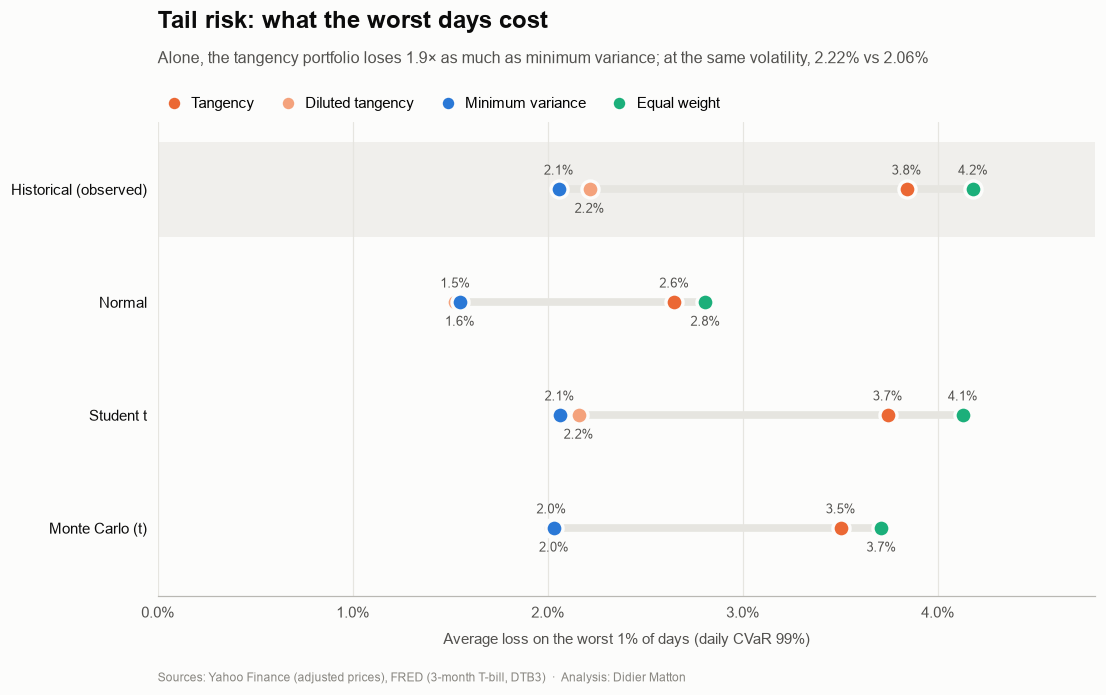

,"Covid crash (Feb 19 – Mar 23, 2020)",Year 2022,Worst day,Max drawdown
Tangency,-18.2%,-19.0%,-11.4%,-27.7%
Diluted tangency,-10.6%,-10.3%,-6.6%,-16.4%
Minimum variance,-7.5%,-18.4%,-4.4%,-24.1%
Equal weight,-20.7%,-29.2%,-12.0%,-36.2%


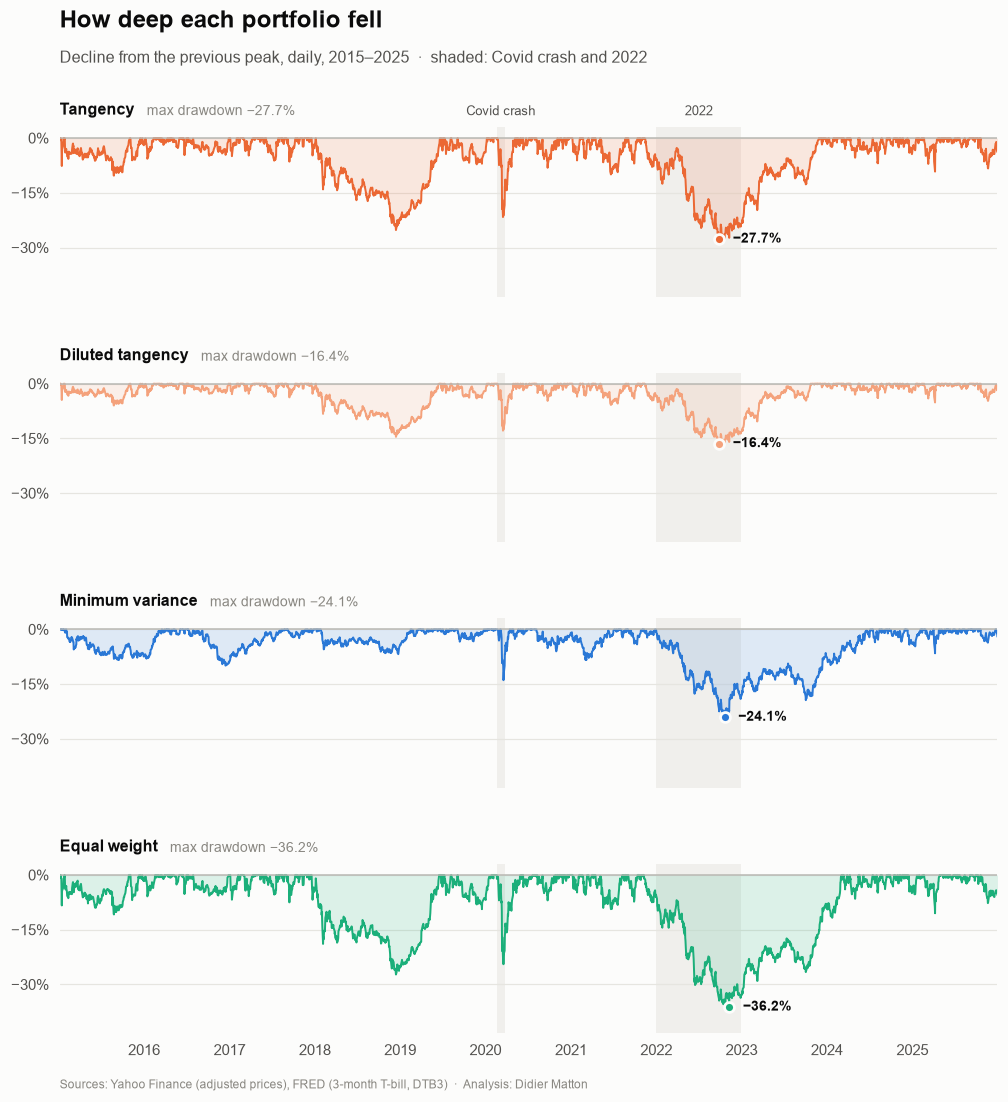

,Weight,Variance contribution,CVaR 99% contribution
Ticker,,,
SPY,31.7%,18.0%,24.9%
TLT,0.0%,0.0%,-0.0%
GLD,51.3%,24.9%,16.9%
VNQ,0.0%,0.0%,-0.0%
BTC-USD,17.1%,57.0%,58.2%


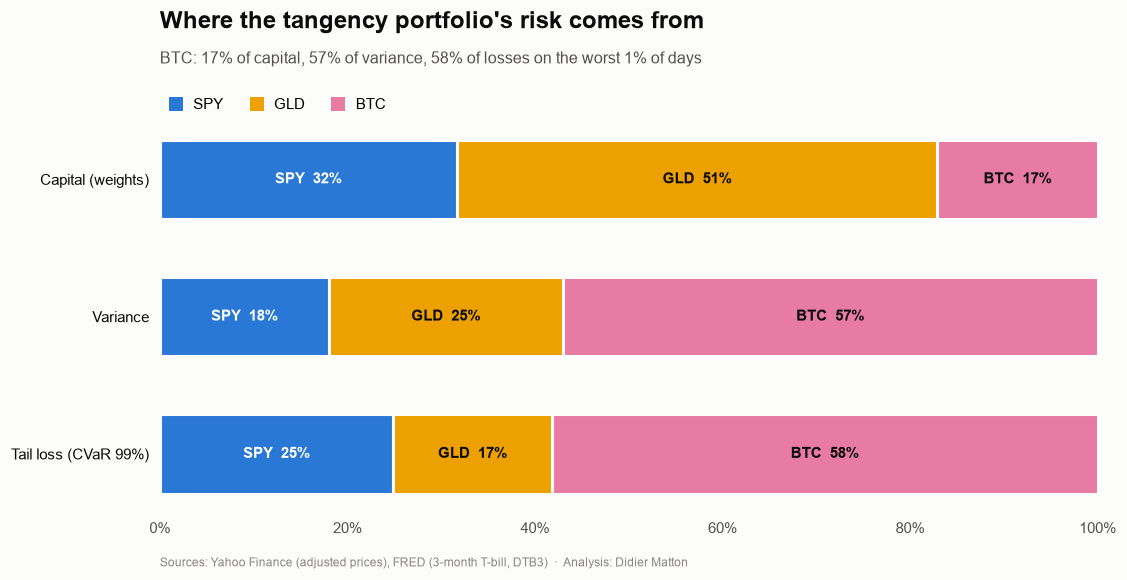

In [13]:
# Step 6 — Execution

# 6.0 Four portfolios: the three of steps 3–4 + the tangency portfolio diluted to the minimum-variance volatility
vol_minvar = np.sqrt(portfolio_variance(w_minvar, cov_annual))
k_dilute = exposure_for_volatility(w_tangent, cov_annual, vol_minvar)
risk_portfolios = {"Tangency": w_tangent, "Diluted tangency": w_tangent,
                   "Minimum variance": w_minvar, "Equal weight": w_eq}
exposure = {"Diluted tangency": k_dilute}
print(f"Diluted tangency: {k_dilute:.1%} tangency portfolio + {1 - k_dilute:.1%} T-bills")

port_r = portfolio_return_series(risk_portfolios, returns, rf_annual, exposure)

# 6.1 Risk profile: equal-risk comparison and shape of the tail
display(risk_profile(port_r, rf_annual).style.format({
    "Return": "{:.2%}", "Volatility": "{:.2%}", "Sharpe": "{:.2f}", "CVaR 99%": "{:.2%}",
    "CVaR / daily vol": "{:.2f}", "Max drawdown": "{:.1%}",
}))
display(tail_statistics(port_r).style.format("{:.2f}"))

# 6.2 Daily VaR and CVaR, four methods, 95% and 99%
risk = risk_table(risk_portfolios, returns, rf_annual, exposure)
display(risk.style.format("{:.2%}"))

plot_cvar_comparison(risk, path="assets/cvar_comparison.png")
plt.show()

# 6.3 Stress tests: actual behaviour during market falls
STRESS_PERIODS = {
    "Covid crash (Feb 19 – Mar 23, 2020)": ("2020-02-19", "2020-03-23"),
    "Year 2022": ("2022-01-01", "2022-12-31"),
}
display(stress_table(port_r, STRESS_PERIODS).style.format("{:.1%}"))

plot_drawdowns(port_r, {"Covid crash": STRESS_PERIODS["Covid crash (Feb 19 – Mar 23, 2020)"],
                        "2022": STRESS_PERIODS["Year 2022"]}, path="assets/drawdowns.png")
plt.show()

# 6.4 Where does the tangency portfolio's risk come from?
contrib = risk_contributions(w_tangent, returns, cov_annual)
display(contrib.style.format("{:.1%}"))

plot_risk_contributions(contrib, path="assets/risk_contributions.png")
plt.show()

**Fat tails: the normal distribution understates extreme risk.** Excess kurtosis ranges from 5.9 to 9.6 and the fitted Student t has 3.6 to 4.5 degrees of freedom, far from a normal distribution. At 99%, the normal CVaR understates the historical CVaR by 31% for the tangency portfolio (2.65% vs 3.84%), 33% for equal weight and 25% for minimum variance. At 95% the normal distribution slightly *overstates* the VaR (1.60% vs 1.48%): the signature of a leptokurtic distribution, with more mass in the centre and in the extremes and less in between. A normal VaR at 95% can look fine while hiding the problem at 99%. The Student t matches the historical figures closely (3.74% vs 3.84%); the Monte Carlo is slightly lower because ν = 5 implies thinner tails than the fitted values (3.6 to 4.5).

**Alone, the tangency portfolio is not the least risky — but that comparison is not like for like.**

| | Volatility | Return | CVaR 99% | CVaR / daily vol | Covid crash | 2022 | Max drawdown |
|---|---|---|---|---|---|---|---|
| Tangency | 16.3% | 23.5% | 3.84% | 3.73 | −18.2% | −19.0% | −27.7% |
| **Diluted tangency** | **9.4%** | **14.4%** | 2.22% | 3.73 | −10.6% | **−10.3%** | **−16.4%** |
| **Minimum variance** | **9.4%** | 8.3% | **2.06%** | 3.46 | **−7.5%** | −18.4% | −24.1% |
| Equal weight | 17.2% | 21.5% | 4.18% | 3.85 | −20.7% | −29.2% | −36.2% |

- **Alone**, the tangency portfolio's CVaR is almost twice that of the minimum-variance portfolio. This is expected: the minimum-variance portfolio is the least volatile by construction.
- **At equal volatility** (diluted tangency vs minimum variance), the picture changes. The diluted tangency portfolio earns almost twice as much, and its tail is barely heavier (CVaR per unit of daily volatility 3.73 vs 3.46; a normal distribution would give 2.67).
- **The type of crisis decides.** In a sudden crash (Covid), minimum variance lost less (−7.5% vs −10.6%). In an inflation and rate shock (2022), the diluted tangency portfolio lost much less (−10.3% vs −18.4%), because the minimum-variance portfolio relied on long-term bonds, which fell with equities. Minimum variance protects against crises that resemble its estimation period.
- **Caveat.** The 2022 comparison is in-sample: the full-sample tangency portfolio holds no TLT partly because it was estimated on data that include the 2022 bond crash. Estimated on 2015–2021 only, it held 38% TLT and fell to $0.69 per dollar in 2022, below the minimum-variance portfolio ($0.75, section 5). The Covid result is robust; the 2022 result and the return advantage (weights chosen with hindsight on gold and Bitcoin) are optimistic for the tangency portfolio.

**The tangency portfolio's risk comes almost entirely from Bitcoin.** Bitcoin is 17% of capital but 57% of the variance and 58% of the CVaR. Gold, at 51% of capital, accounts for only 17% of the CVaR: it cushions the worst days. SPY's share of risk rises from 18% (variance) to 25% (CVaR): equities weigh more on the worst days, consistent with correlations rising when markets fall.

## 7. Conclusion

**Question:** is the Sharpe-optimal portfolio also the least risky when markets fall?

**Answer: not in absolute terms — and at equal risk, it depends on the type of crisis.**

- **Held alone**, the tangency portfolio (16.3% volatility) loses almost twice as much as the minimum-variance portfolio on its worst 1% of days (99% CVaR of 3.84% vs 2.06%). This is expected: the minimum-variance portfolio is the least volatile by construction.
- **At equal risk**, as the capital market line prescribes, about 58% tangency and 42% T-bills give the same 9.4% volatility as the minimum-variance portfolio. In-sample, this diluted tangency portfolio earns almost twice as much (14.4% vs 8.3%) with a tail that is barely heavier (CVaR 2.22% vs 2.06%).
- **The type of crisis decides**: minimum variance lost less in the sudden Covid crash (−7.5% vs −10.6%), the diluted tangency portfolio lost much less in the 2022 rate shock (−10.3% vs −18.4%). The 2022 result is in-sample and optimistic: estimated on 2015–2021 only, the tangency portfolio held 38% TLT and fell to $0.69 in 2022, below minimum variance ($0.75, section 5).

**Key findings**

1. **Volatility misses the shape of the tail, but per unit of risk the tails are similar.** All portfolios have fat tails (excess kurtosis between 5.9 and 9.6): a normal VaR understates the 99% CVaR by 25% to 33%, while the Student t closely matches historical risk. Measured in daily volatilities, the 99% CVaR stays between 3.46 and 3.85 for all portfolios.
2. **The tangency portfolio's tail risk is concentrated in Bitcoin**: 17% of capital, 57% of variance and 58% of CVaR. The optimizer accepts it because its past mean return offsets its volatility, not because it is low-risk.
3. **Minimum-variance protection is a bet on correlations.** It relies on long-term bonds hedging equities: it worked in the Covid crash and failed in 2022, when stocks and bonds fell together.
4. **Optimal weights are unstable and their out-of-sample edge is not demonstrated.** Tangency weights shift sharply across 3-year windows (SPY from 1% to 82%, GLD from 0% to 79%). Estimated on 2015–2021, the equal-weight portfolio came out ahead on 2022–2025 (Sharpe 0.43 vs 0.24 for tangency and 0.11 for minimum variance), but on a single 4-year split, with a standard error of about 0.5, these differences are not statistically significant.

**In practice,** the tangency portfolio combined with cash is a sensible risky core at equal risk, but its weights should not be implemented as estimated. A robust allocation should control tail risk (CVaR constraint, per-asset caps, risk budgeting), avoid relying on a single hedge such as long bonds, and account for estimation error in expected returns.

**Limitations**
- Weights in sections 3, 4 and 6 are estimated on the full sample (in-sample analysis).
- Constant weights (implicit daily rebalancing), no transaction costs; a single out-of-sample split.
- The diluted portfolio lends at the T-bill rate (no borrowing is needed, since less than 100% is invested in the tangency portfolio).
- US trading calendar: Bitcoin's weekend moves are folded into Monday's return.
- Five assets, long-only. Monte Carlo with a fixed ν = 5.

**References**
- Markowitz, H. (1952). Portfolio Selection. *Journal of Finance*, 7(1), 77–91.
- Sharpe, W. F. (1964). Capital Asset Prices: A Theory of Market Equilibrium under Conditions of Risk. *Journal of Finance*, 19(3), 425–442.
- Chopra, V. K., & Ziemba, W. T. (1993). The Effect of Errors in Means, Variances, and Covariances on Optimal Portfolio Choice. *Journal of Portfolio Management*, 19(2), 6–11.
- Rockafellar, R. T., & Uryasev, S. (2000). Optimization of Conditional Value-at-Risk. *Journal of Risk*, 2(3), 21–41.
- Lo, A. W. (2002). The Statistics of Sharpe Ratios. *Financial Analysts Journal*, 58(4), 36–52.
- DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal Versus Naive Diversification: How Inefficient Is the 1/N Portfolio Strategy? *Review of Financial Studies*, 22(5), 1915–1953.

---
**Didier Matton** | Financial Engineer | Full-Stack Data Scientist | Python, Django, VBA, BI & LLMs | Quantitative Finance